# Syllables and neuromodulator signals

Which syllables go with each neuromodulator's photometry signal, trial by trial? This notebook uses **every session of the photometry export that also has syllables**, with no DDM-HMM needed: 5 neuromodulators and 36 mice.

**Data**
- **Photometry**: `neuromodulators/pose_qc_hmm_k4`. This is the preprocessed, z-scored GCaMP signal from −1 to +1 s around stimulus onset and around feedback, at 30 Hz, with one row per fiber. Sessions with two fibers contribute each fiber separately.
- **Syllables**: the left paw + wheel run, k = 8 (`states_files_left_paw_wheel_k8_own_lick-100ms`). Its codes are read on the photometry's time grid (same clock, 30 Hz), with no time-warping.
- **Windows and masks**: from `Functions/event_psth.py`, the same as in notebooks 4–5. Each trial's samples are limited to its own trial and epoch.
- **Correlation code**: `Functions/syllable_photometry.py`.

**Method**
- At each sample and within one fiber-session and one outcome, the photometry value is correlated across trials with a syllable indicator (1 if the trial is in that syllable at that sample).
- **Partial** version (the default): both are first residualised on log RT, |contrast| level, trial position and trial position², fitted separately at every sample. This removes the obvious shared drivers: slow vs fast trials, stimulus strength, and drift within the session.
- **Aggregation**: Fisher z is averaged per mouse, then across mice. Mice are the unit: dots mark FDR q < 0.05 in a t-test across mice, computed within each map. Rewarded and error trials are kept separate throughout.

In [1]:
import sys, pathlib, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'syllable_photometry.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'paper-individuality'))
from Functions import ddm_hmm as dh
from Functions import event_psth as ep
from Functions import syllable_photometry as sp
import paper_style as ps
ps.use('paper')
for msg in ['Mean of empty slice', 'Degrees of freedom', 'invalid value encountered', 'Precision loss', 'divide by zero', 'After omitting NaNs']:
    warnings.filterwarnings('ignore', message=msg)

DATA = REPO / 'paper-individuality' / 'data' / 'neuromodulators'
RUN = 'left_paw_wheel_k8_own_lick-100ms'
STATES_DIR = DATA / f'states_files_{RUN}'
CACHE = DATA / 'syllables_photometry'
CACHE.mkdir(exist_ok=True)
RECOMPUTE = False
cfg = json.loads((STATES_DIR / '_config.json').read_text())
assert cfg['relabel'] is None
PALETTE = pd.read_csv(pathlib.Path(cfg['states_dir']) / 'state_palette.csv', index_col='state')
N_PAW, PAW_COLORS = len(PALETTE), PALETTE['colour'].tolist()
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
MIN_TRIALS = 20

rec = pd.read_csv(dh.ARCHIVE / 'recordings.csv')
have_syll = {p.name.split('_')[3] for p in STATES_DIR.glob('*_states_file_*')}
rec = rec[rec['eid'].isin(have_syll)].reset_index(drop=True)
trials = sp.session_trials(rec['eid'].unique())
STIM, FB, meta = ep.photometry_windows(rec, trials)
SYL_S, SYL_F = ep.syllable_windows(meta, STATES_DIR)
TIME, QP = ep.TIME, float(meta['quiescencePeriod'].median())

cov = (rec.groupby('target_NM').agg(fibers=('eid', 'size'), sessions=('eid', 'nunique'), mice=('subject', 'nunique'))
       .reindex(NM_ORDER))
cov['go trials (fiber rows)'] = meta.groupby('target_NM').size()
both = ~np.isnan(STIM) & ~np.isnan(SYL_S)
cov['syllable code on unmasked samples'] = (pd.Series((~np.isnan(SYL_S) & ~np.isnan(STIM)).sum(1) / np.maximum((~np.isnan(STIM)).sum(1), 1))
                                            .groupby(meta['target_NM']).mean().round(3))
cov

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


,fibers,sessions,mice,go trials (fiber rows),syllable code on unmasked samples
target_NM,,,,,
DR-5HT,140,140,9,107136,0.989
VTA-DA,141,141,7,108963,0.982
SNc-DA,65,65,6,45314,0.994
LC-NE,96,96,8,72246,0.988
NBM-ACh,75,50,7,63786,0.994


## The signals and the behaviour, per neuromodulator

These plots give context for the correlation maps. Each block covers one neuromodulator and one outcome, using all of its fiber-sessions. The rows are:
1. the photometry PSTH (mean ± SEM across fiber-sessions);
2. the paw-state composition, stacked from still (top) to most vigorous (bottom);
3. P(whisking) as a band and P(licking) as a line.

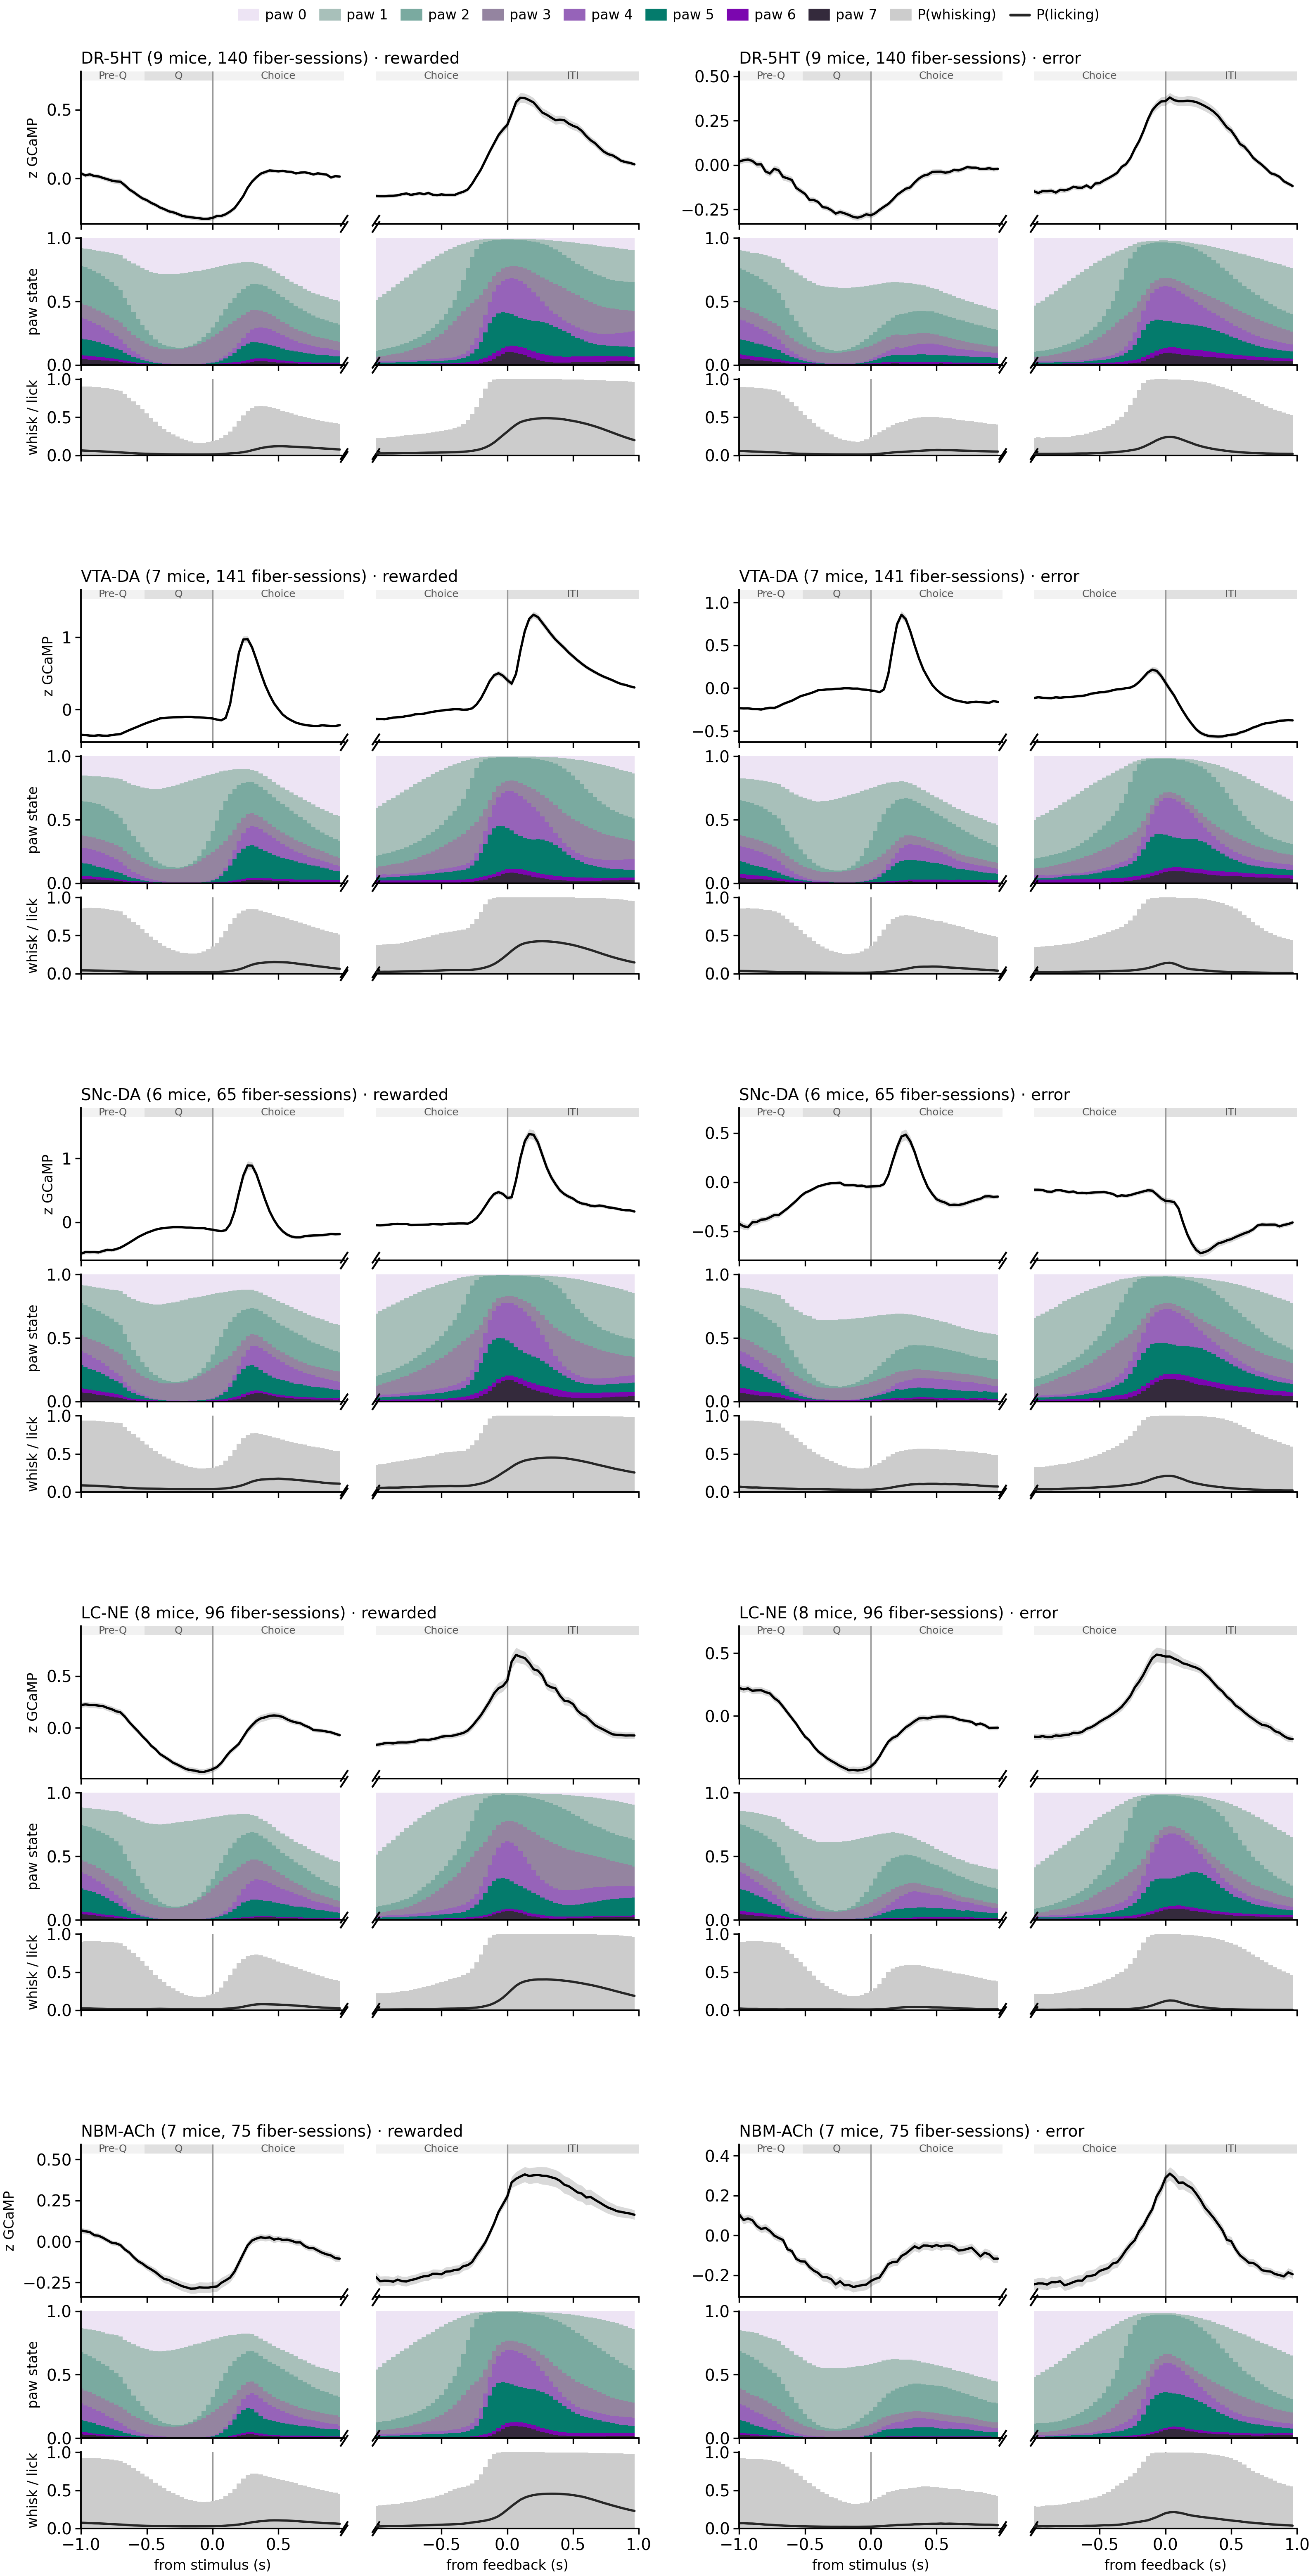

In [2]:
sem = lambda X: np.nanstd(X, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(X), axis=0))

def per_session(m, fn_s, fn_f):
    # (fiber-sessions x T) per window of a per-trial quantity, averaged within fiber-session
    s, f = [], []
    for _, g in m.groupby(['eid', 'region']):
        if len(g) < MIN_TRIALS:
            continue
        idx = g.index.to_numpy()
        s.append(np.nanmean(fn_s(idx), 0)); f.append(np.nanmean(fn_f(idx), 0))
    return np.vstack(s), np.vstack(f)

def paw_onehot(C, idx, k):
    c = C[idx]
    return np.where(np.isnan(c), np.nan, (c % N_PAW) == k)

def stack(ax, comp):
    top = np.ones(len(TIME))
    for k in range(N_PAW):
        ax.fill_between(TIME, top - comp[k], top, color=PAW_COLORS[k], lw=0, step='mid')
        top = top - comp[k]
    ax.set_ylim(0, 1)

fig = plt.figure(figsize=(9.5, 3.5 * len(NM_ORDER)))
outer = fig.add_gridspec(len(NM_ORDER), 2, wspace=0.18, hspace=0.35, top=0.96)
for row, nm in enumerate(NM_ORDER):
    for col, (outcome, oname) in enumerate([(1, 'rewarded'), (0, 'error')]):
        m = meta[(meta['target_NM'] == nm) & (meta['correct'] == outcome)]
        block = outer[row, col].subgridspec(3, 1, height_ratios=[1.2, 1, 0.6], hspace=0.12)
        a, b = ep.split_panels(fig, block[0], f"{nm} ({cov.loc[nm, 'mice']} mice, {cov.loc[nm, 'fibers']} fiber-sessions) · {oname}",
                               epochs=True, qp=QP, xlabels=False)
        S, F = per_session(m, lambda i: STIM[i], lambda i: FB[i])
        for ax, X in [(a, S), (b, F)]:
            mu, se = np.nanmean(X, 0), sem(X)
            ax.fill_between(TIME, mu - se, mu + se, color='k', alpha=0.15, lw=0); ax.plot(TIME, mu, color='k', lw=1)
        ep.share_ylim(a, b)
        if col == 0:
            a.set_ylabel('z GCaMP', fontsize=6)
        comp = [per_session(m, lambda i, k=k: paw_onehot(SYL_S, i, k), lambda i, k=k: paw_onehot(SYL_F, i, k))
                for k in range(N_PAW)]
        cs = np.vstack([np.nanmean(c[0], 0) for c in comp]); cf = np.vstack([np.nanmean(c[1], 0) for c in comp])
        a2, b2 = ep.split_panels(fig, block[1], epochs=False, xlabels=False)
        stack(a2, cs / cs.sum(0)); stack(b2, cf / cf.sum(0))
        if col == 0:
            a2.set_ylabel('paw state', fontsize=6)
        a3, b3 = ep.split_panels(fig, block[2], epochs=False, xlabels=(row == len(NM_ORDER) - 1))
        W = per_session(m, lambda i: np.where(np.isnan(SYL_S[i]), np.nan, (SYL_S[i] // N_PAW) % 2),
                        lambda i: np.where(np.isnan(SYL_F[i]), np.nan, (SYL_F[i] // N_PAW) % 2))
        Lk = per_session(m, lambda i: SYL_S[i] // (2 * N_PAW), lambda i: SYL_F[i] // (2 * N_PAW))
        for ax, w in [(a3, 0), (b3, 1)]:
            ax.fill_between(TIME, 0, np.nanmean(W[w], 0), color='0.8', lw=0, step='mid')
            ax.plot(TIME, np.nanmean(Lk[w], 0), color='0.15', lw=1); ax.set_ylim(0, 1)
        if col == 0:
            a3.set_ylabel('whisk / lick', fontsize=6)
handles = [Patch(color=PAW_COLORS[k], label=f'paw {k}') for k in range(N_PAW)] + \
          [Patch(color='0.8', label='P(whisking)'), Line2D([], [], color='0.15', label='P(licking)')]
fig.legend(handles=handles, loc='upper center', ncol=10, frameon=False, fontsize=6, bbox_to_anchor=(0.5, 0.985))
plt.show()

## Correlations: compute (cached)

There are three runs:
- factored features (8 paw states, whisking, licking), partial;
- the same features, raw (no covariates);
- full syllables (codes that take at least 1% of samples), partial.

Each is cached in `CACHE`. Set `RECOMPUTE = True` above to redo them; together they take a few minutes.

In [3]:
codes = np.concatenate([SYL_S[~np.isnan(SYL_S)], SYL_F[~np.isnan(SYL_F)]]).astype(int)
share = np.bincount(codes, minlength=4 * N_PAW) / len(codes)
COMMON = sorted(np.flatnonzero(share >= 0.01), key=lambda c: (c // (2 * N_PAW), (c // N_PAW) % 2, c % N_PAW))

RUNS = {'factored_partial': (sp.factored_features(N_PAW), True),
        'factored_raw': (sp.factored_features(N_PAW), False),
        'syllables_partial': (sp.syllable_features(COMMON, N_PAW), True)}
RES = {}
for name, (feats, partial) in RUNS.items():
    f = CACHE / f'corr_{name}_{RUN}.pkl'
    if f.exists() and not RECOMPUTE:
        RES[name] = pd.read_pickle(f)
    else:
        RES[name] = sp.correlations(meta, STIM, FB, SYL_S, SYL_F, feats, partial=partial, min_trials=MIN_TRIALS)
        RES[name].to_pickle(f)
SUM = {k: sp.summarise(v) for k, v in RES.items()}
print({k: len(v) for k, v in RES.items()}, 'fiber-session x outcome maps')

{'factored_partial': 1034, 'factored_raw': 1034, 'syllables_partial': 1034} fiber-session x outcome maps


## Correlation maps: factored features, partial

Rows are paw states 0–7 (stillest to most vigorous, swatch = palette colour), then whisking and licking. Colour gives r across trials after removing log RT, contrast and trial position, averaged over mice. Dots mark FDR q < 0.05 in a t-test across mice. These tests need at least 3 mice, so SNc-DA (6 mice) qualifies but 1–2-mouse subsets would not.

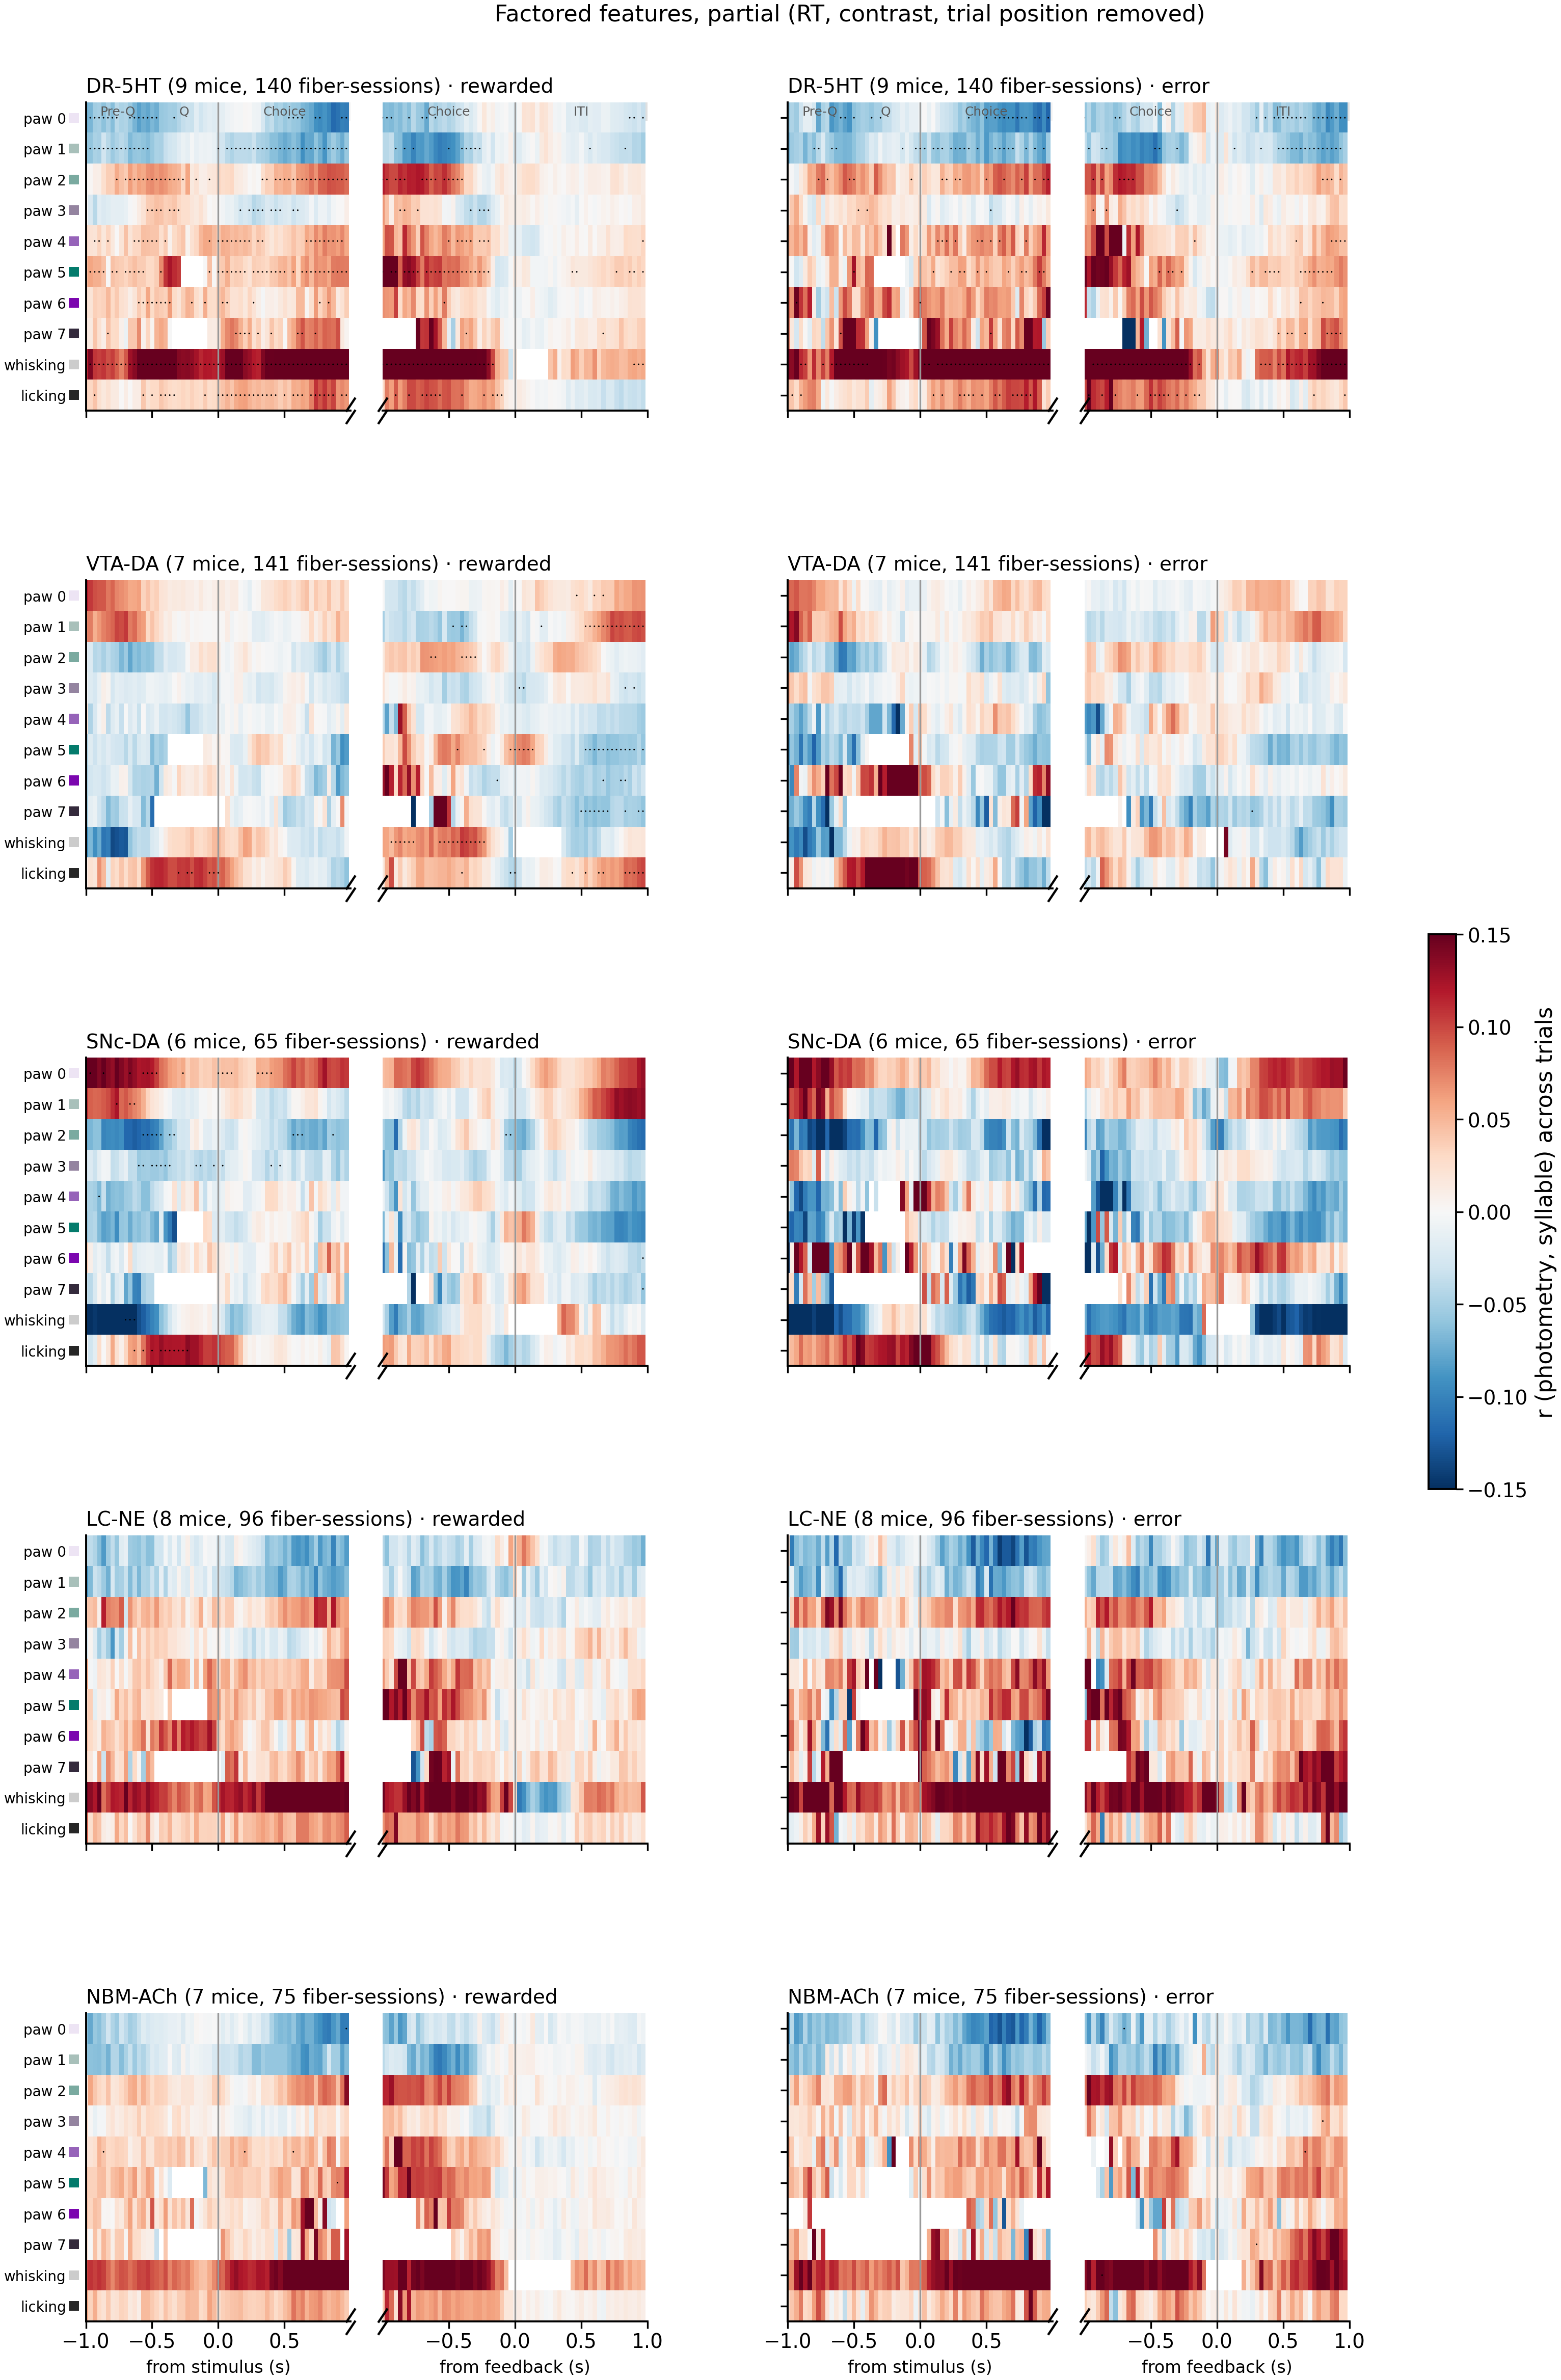

In [4]:
def plot_maps(summary, names, row_colors=None, lim=0.15, title=''):
    fig = plt.figure(figsize=(10, (0.15 * len(names) + 0.8) * len(NM_ORDER) + 0.6))
    outer = fig.add_gridspec(len(NM_ORDER), 2, wspace=0.25, hspace=0.55, top=0.95, bottom=0.05)
    h = (TIME[1] - TIME[0]) / 2
    for row, nm in enumerate(NM_ORDER):
        for col, (outcome, oname) in enumerate([(1.0, 'rewarded'), (0.0, 'error')]):
            e = summary[(nm, outcome)]
            a, b = ep.split_panels(fig, outer[row, col], f"{nm} ({e['n_mice']} mice, {e['n_sessions']} fiber-sessions) · {oname}",
                                   epochs=(row == 0), qp=QP, xlabels=(row == len(NM_ORDER) - 1))
            for w, ax in enumerate((a, b)):
                im = ax.imshow(e['r'][w], aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim, interpolation='nearest',
                               extent=(TIME[0] - h, TIME[-1] + h, len(names) - 0.5, -0.5))
                yy, xx = np.nonzero(e['q'][w] < 0.05)
                ax.scatter(TIME[xx], yy, s=1.2, c='k', marker='.', lw=0)
                ax.set_xlim(-1, 1); ax.set_ylim(len(names) - 0.5, -0.5)
            a.set_yticks(range(len(names)), names if col == 0 else [], fontsize=5)
            if row_colors is not None and col == 0:
                a.scatter(np.full(len(names), -1.09), range(len(names)), marker='s', s=12, c=row_colors, clip_on=False)
                a.tick_params(axis='y', pad=7, length=0)
    fig.colorbar(im, ax=fig.axes, shrink=0.25, label='r (photometry, syllable) across trials')
    fig.suptitle(title, fontsize=8, y=0.99)
    plt.show()

NAMES_F = RES['factored_partial'].attrs['features']
FCOL = PAW_COLORS + ['0.8', '0.15']
plot_maps(SUM['factored_partial'], NAMES_F, FCOL, title='Factored features, partial (RT, contrast, trial position removed)')

### The same without covariates (raw), for comparison

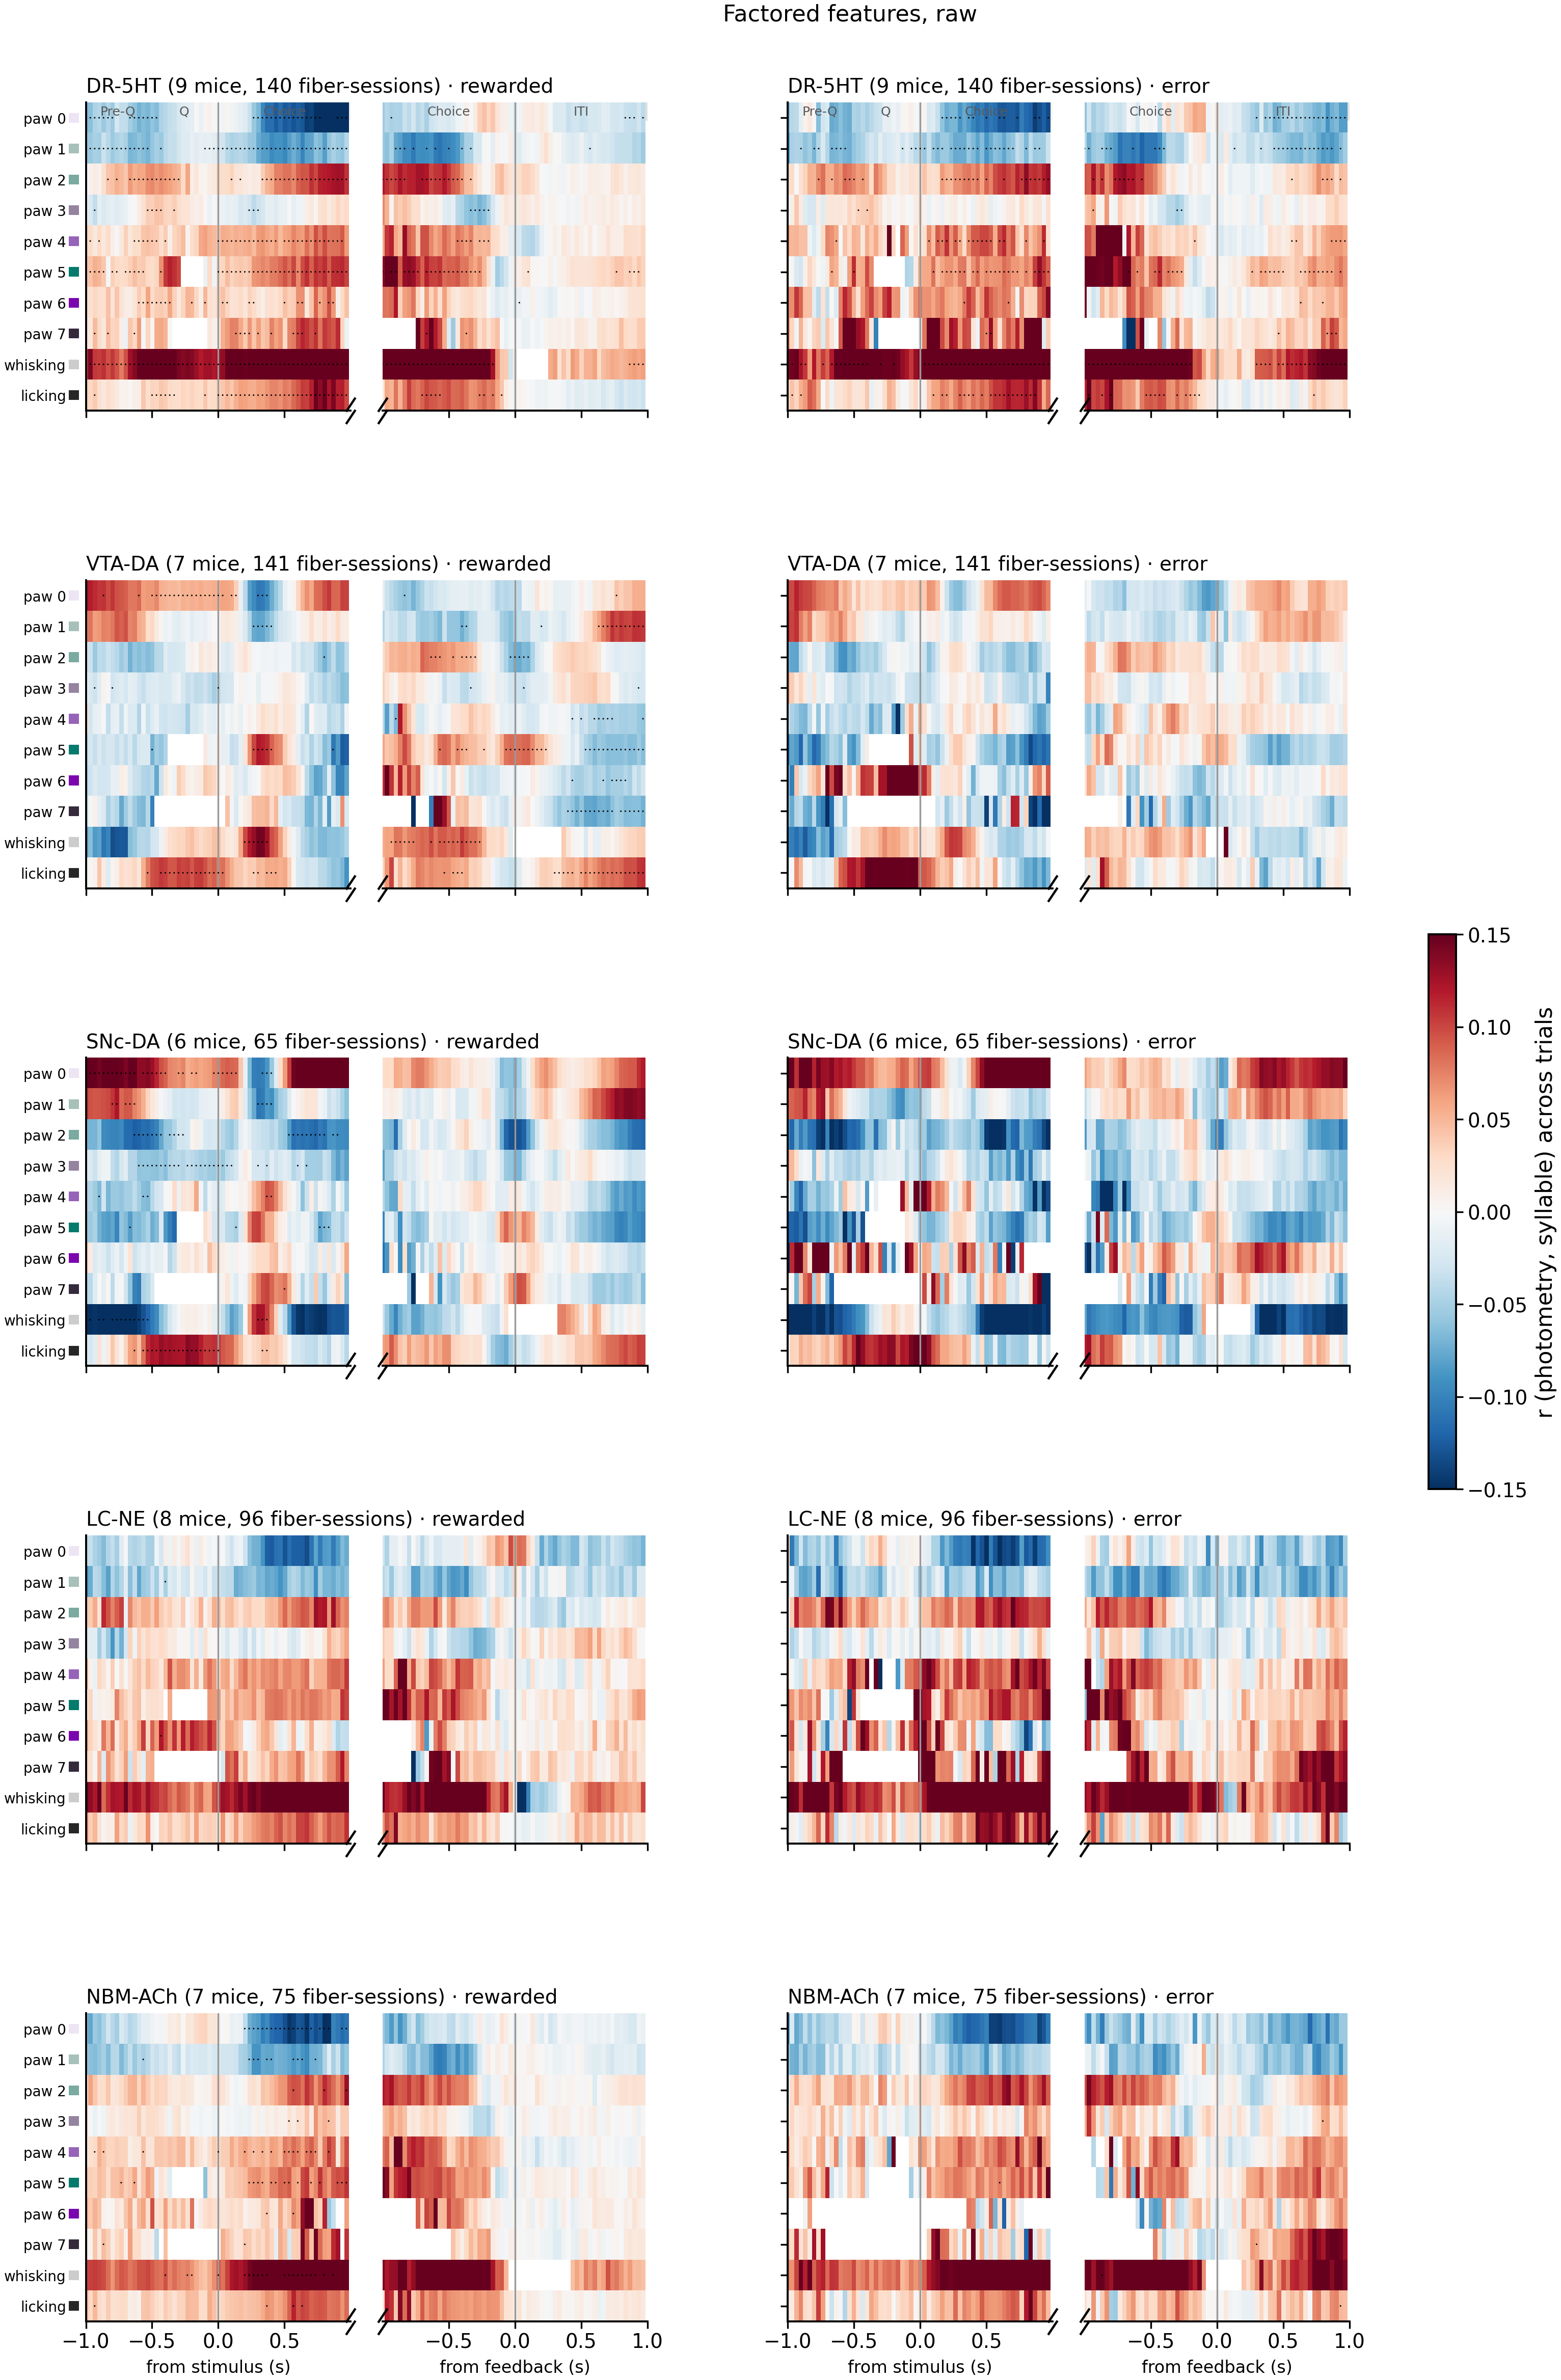

In [5]:
plot_maps(SUM['factored_raw'], NAMES_F, FCOL, title='Factored features, raw')

### How much do the covariates take away?

For each neuromodulator and outcome, the table compares the median |r| over all feature × sample cells, and the fraction of cells with q < 0.05, between the raw and partial maps.

In [6]:
rows = []
for (nm, outcome), e in SUM['factored_partial'].items():
    raw = SUM['factored_raw'][(nm, outcome)]
    rp = np.concatenate([x.ravel() for x in e['r']]); rr = np.concatenate([x.ravel() for x in raw['r']])
    qp_ = np.concatenate([x.ravel() for x in e['q']]); qr = np.concatenate([x.ravel() for x in raw['q']])
    rows.append({'NM': nm, 'outcome': 'rewarded' if outcome == 1 else 'error',
                 'median |r| raw': np.nanmedian(np.abs(rr)), 'median |r| partial': np.nanmedian(np.abs(rp)),
                 'cells q<.05 raw': np.nanmean(qr < 0.05), 'cells q<.05 partial': np.nanmean(qp_ < 0.05)})
pd.DataFrame(rows).set_index(['NM', 'outcome']).reindex(NM_ORDER, level=0).round(3)

median |r| raw  median |r| partial  cells q<.05 raw  \
NM      outcome                                                         
DR-5HT  error              0.050               0.048            0.287   
        rewarded           0.037               0.035            0.374   
VTA-DA  error              0.032               0.027            0.000   
        rewarded           0.033               0.026            0.168   
SNc-DA  error              0.051               0.048            0.000   
        rewarded           0.035               0.031            0.112   
LC-NE   error              0.052               0.050            0.000   
        rewarded           0.041               0.037            0.002   
NBM-ACh error              0.048               0.045            0.004   
        rewarded           0.032               0.028            0.081   

                  cells q<.05 partial  
NM      outcome                        
DR-5HT  error                   0.245  
        rewarded                0.362  
VTA-DA  error                   0.001  
        rewarded                0.084  
SNc-DA  error                   0.000  
        rewarded                0.052  
LC-NE   error                   0.000  
        rewarded                0.000  
NBM-ACh error                   0.004  
        rewarded                0.004

## Mouse by mouse, for the three most interpretable features

The features are still paw (paw 0), whisking and licking, using partial r. Thin lines are individual mice and the thick line is their mean, so this shows whether the map averages hide mice of opposite sign. Rewarded trials only.

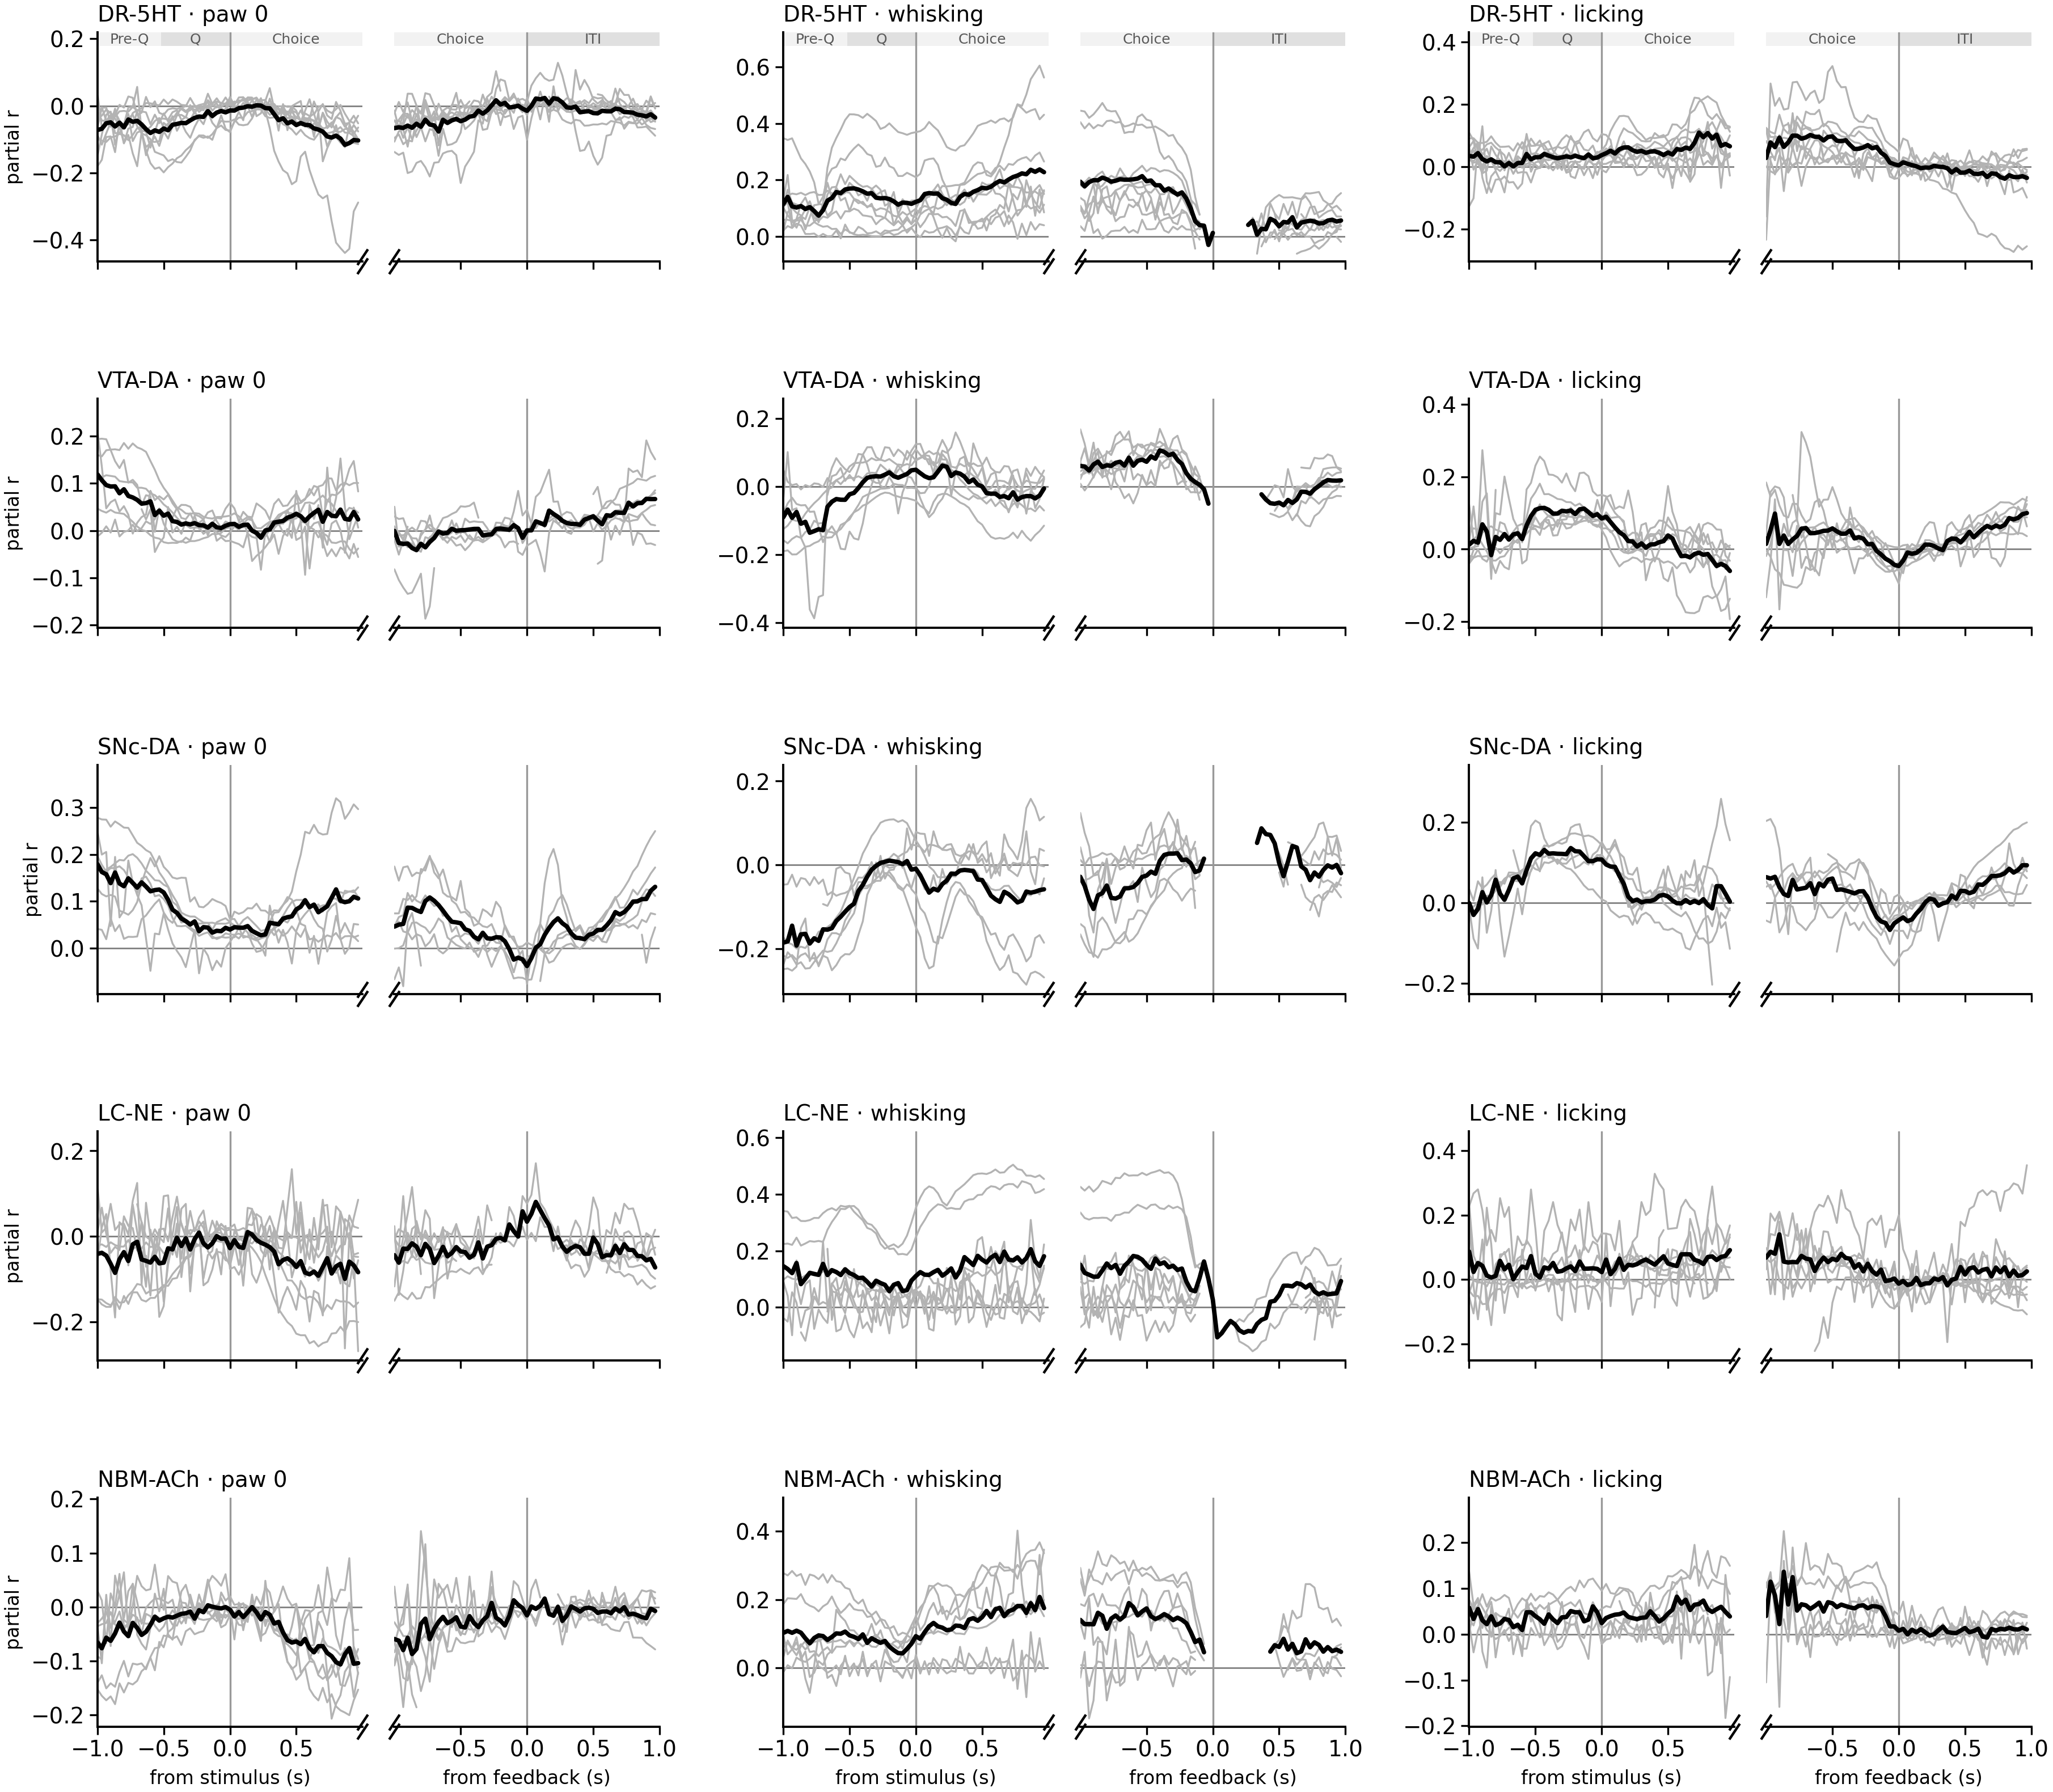

In [7]:
SHOW = ['paw 0', 'whisking', 'licking']
fig = plt.figure(figsize=(11, 1.7 * len(NM_ORDER) + 0.5))
outer = fig.add_gridspec(len(NM_ORDER), len(SHOW), wspace=0.22, hspace=0.6, top=0.94)
for row, nm in enumerate(NM_ORDER):
    e = SUM['factored_partial'][(nm, 1.0)]
    for col, feat in enumerate(SHOW):
        fi = NAMES_F.index(feat)
        a, b = ep.split_panels(fig, outer[row, col], f'{nm} · {feat}' if True else None, epochs=(row == 0), qp=QP,
                               xlabels=(row == len(NM_ORDER) - 1))
        for w, ax in enumerate((a, b)):
            for mrow in e['mice'][w]:
                ax.plot(TIME, mrow[fi], color='0.7', lw=0.6)
            ax.plot(TIME, e['r'][w][fi], color='k', lw=1.4)
            ax.axhline(0, color='0.5', lw=0.5, zorder=0)
        ep.share_ylim(a, b)
        if col == 0:
            a.set_ylabel('partial r', fontsize=6)
plt.show()

## Full syllables, partial

Each code combines a paw state with whisking (+W) and licking (+L). Only codes that take at least 1% of all samples are shown. Rows are ordered by lick, then whisk, then paw state.

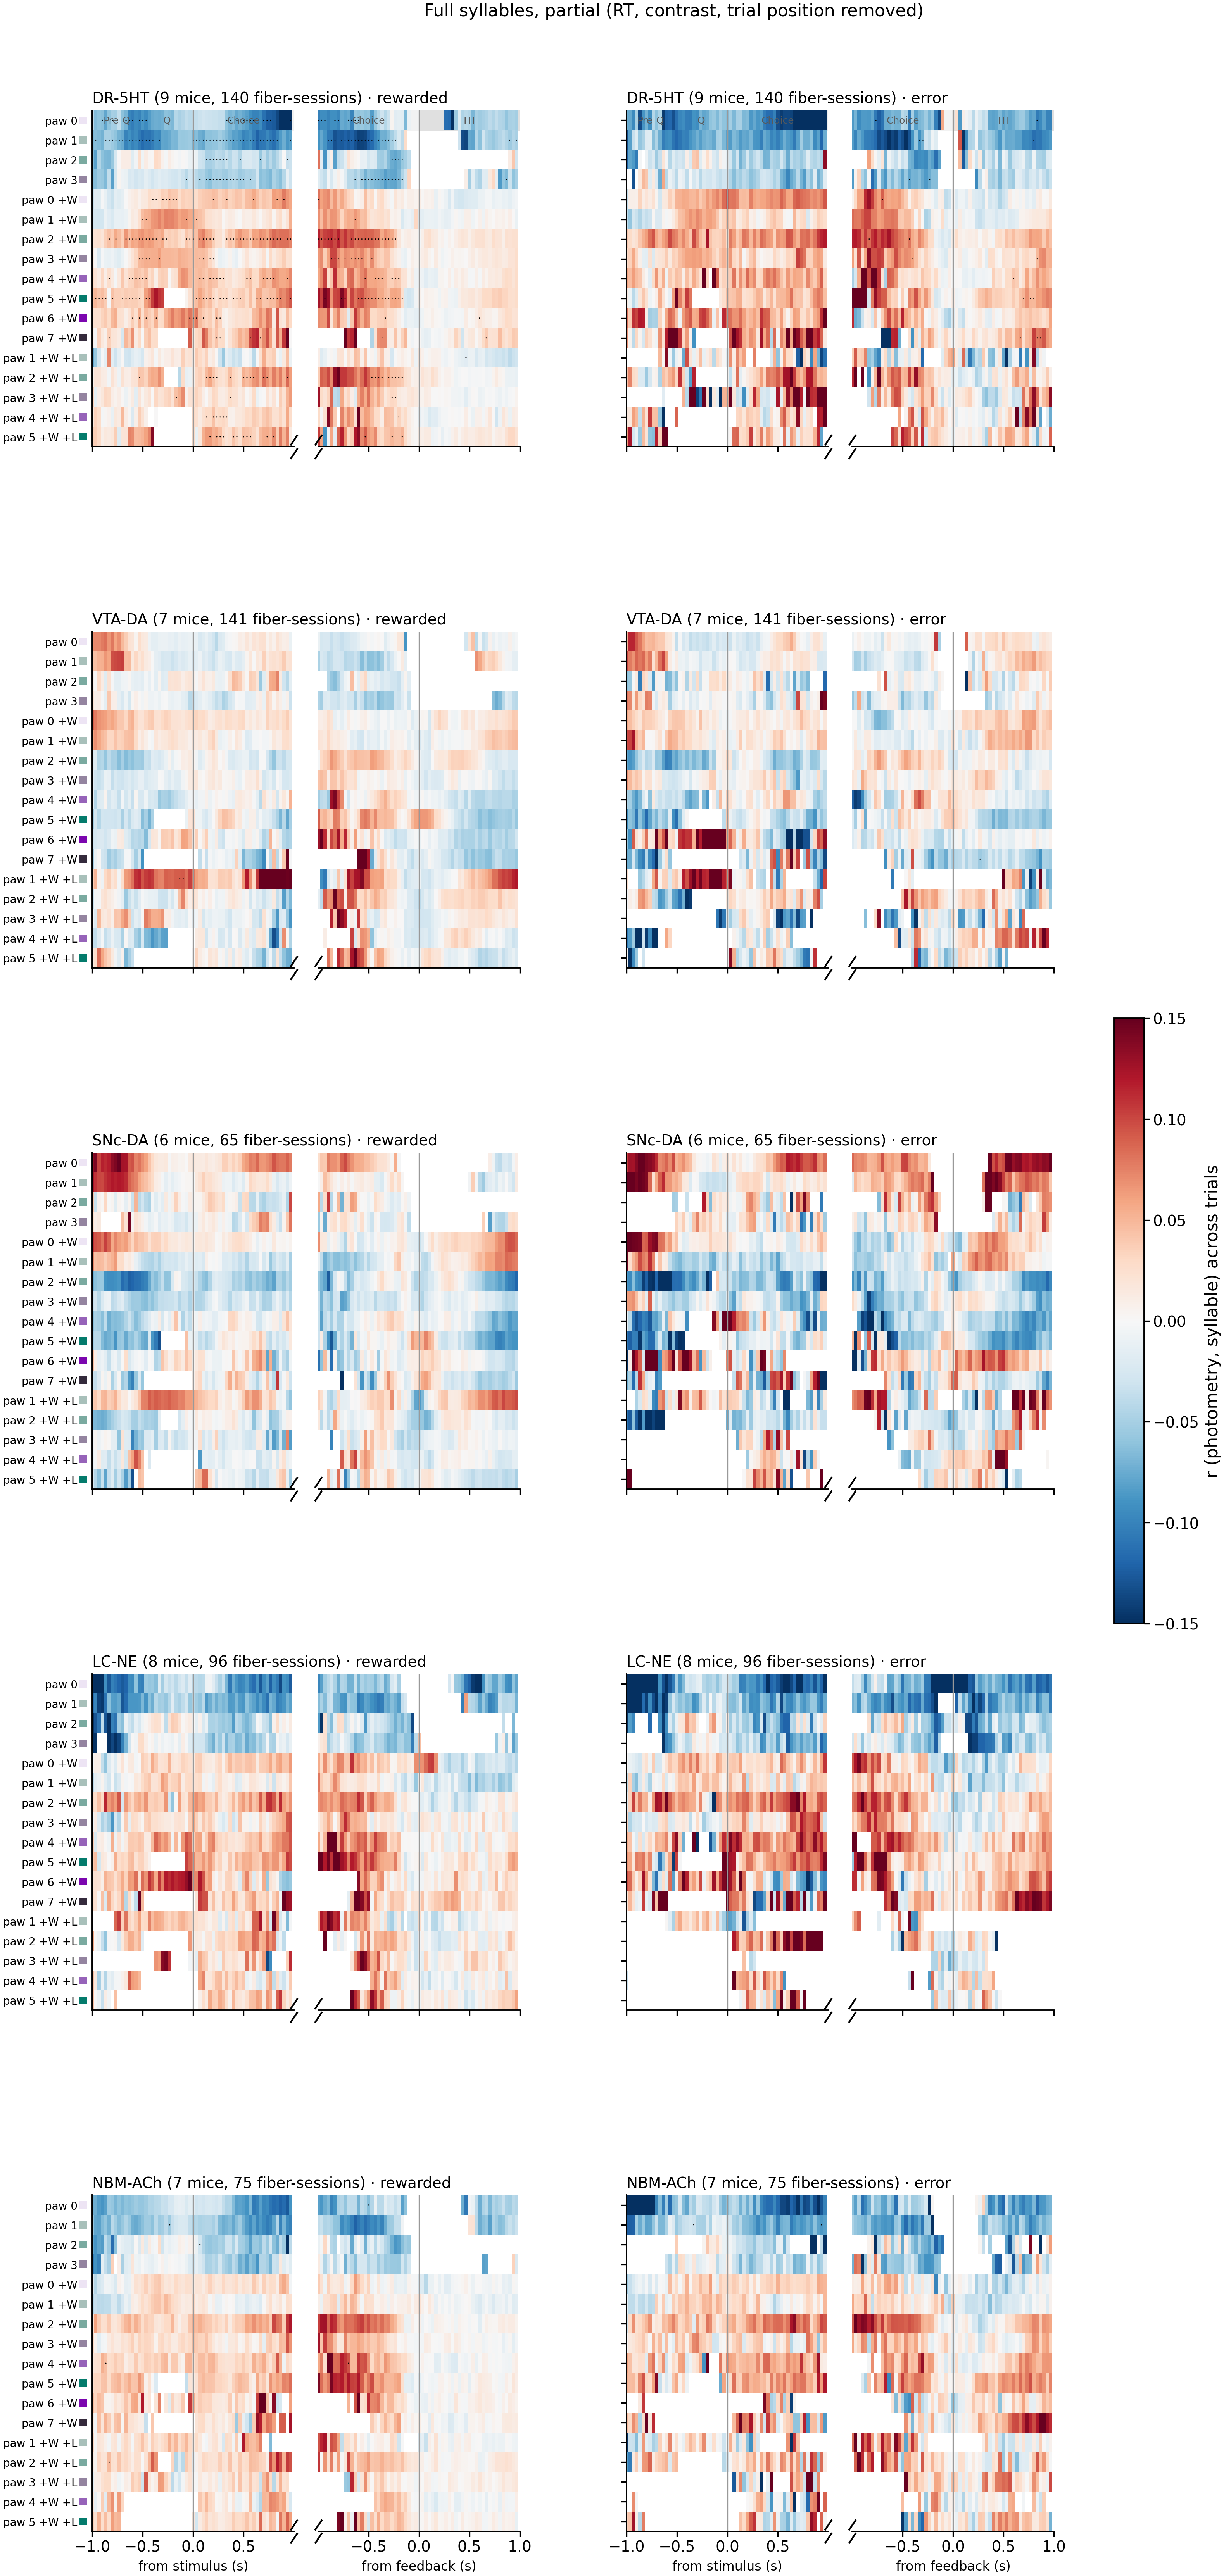

In [8]:
NAMES_S = RES['syllables_partial'].attrs['features']
plot_maps(SUM['syllables_partial'], NAMES_S, [PAW_COLORS[int(n.split()[1])] for n in NAMES_S],
          title='Full syllables, partial (RT, contrast, trial position removed)')

## The strongest relations

These come from the factored, partial maps. For each neuromodulator and outcome, the table lists every feature's peak |r| among cells with q < 0.05, keeping the top 5. `mice same sign` is the fraction of mice whose r at that cell has the sign of the mean.

In [9]:
rows = []
for (nm, outcome), e in SUM['factored_partial'].items():
    for w, wname in enumerate(['stim', 'fb']):
        for fi, ti in zip(*np.nonzero(e['q'][w] < 0.05)):
            rows.append({'NM': nm, 'outcome': 'rewarded' if outcome == 1 else 'error', 'window': wname,
                         'time (s)': TIME[ti], 'feature': NAMES_F[fi], 'r': e['r'][w][fi, ti],
                         'mice same sign': e['agree'][w][fi, ti], 'n mice': e['n_mice']})
top = pd.DataFrame(rows)
TOP = (top.assign(absr=top['r'].abs()).sort_values('absr', ascending=False)
       .groupby(['NM', 'outcome', 'feature']).head(1).groupby(['NM', 'outcome']).head(5)
       .drop(columns='absr'))
TOP['NM'] = pd.Categorical(TOP['NM'], NM_ORDER)
TOP.sort_values(['NM', 'outcome', 'r']).round(3).reset_index(drop=True)

,NM,outcome,window,time (s),feature,r,mice same sign,n mice
0,DR-5HT,error,fb,-0.733,paw 2,0.120,0.889,9
1,DR-5HT,error,stim,-0.500,paw 5,0.125,0.556,9
2,DR-5HT,error,stim,-0.933,paw 6,0.147,0.667,9
3,DR-5HT,error,fb,-0.967,licking,0.152,0.667,9
4,DR-5HT,error,stim,0.967,whisking,0.262,1.000,9
5,DR-5HT,rewarded,stim,0.967,paw 0,-0.103,1.000,9
6,DR-5HT,rewarded,stim,0.733,licking,0.109,1.000,9
7,DR-5HT,rewarded,fb,-1.000,paw 2,0.119,0.889,9
8,DR-5HT,rewarded,fb,-0.900,paw 5,0.174,0.778,9
9,DR-5HT,rewarded,stim,0.933,whisking,0.237,1.000,9


## Correlations over all samples: syllable use and NM signal, wherever in the PSTH

This section asks a simpler question: **is the NM signal higher whenever the mouse uses syllable X?** It ignores the position in the PSTH.

**Method**
- For each fiber-session, every valid sample is pooled: both windows, every go trial, both outcomes.
- The photometry value is correlated with the syllable indicator over all of them, then averaged per mouse and across mice.
- Stars mark FDR q < 0.05 (over syllables, within neuromodulator) in a t-test across mice.

**Two versions**
- **pooled**: the raw relation. This includes the shared time course. For example, if licking happens after reward and dopamine peaks after reward, licking correlates with dopamine.
- **PSTH-centred**: before correlating, the photometry and the indicator have their mean at each (outcome, window, sample) subtracted within the fiber-session. What remains is the trial-to-trial part, now summarised over the whole PSTH.

The gap between the two shows how much of a syllable's link to the NM comes from *when* the syllable happens in the trial.

Full syllables come first, then the factored features.

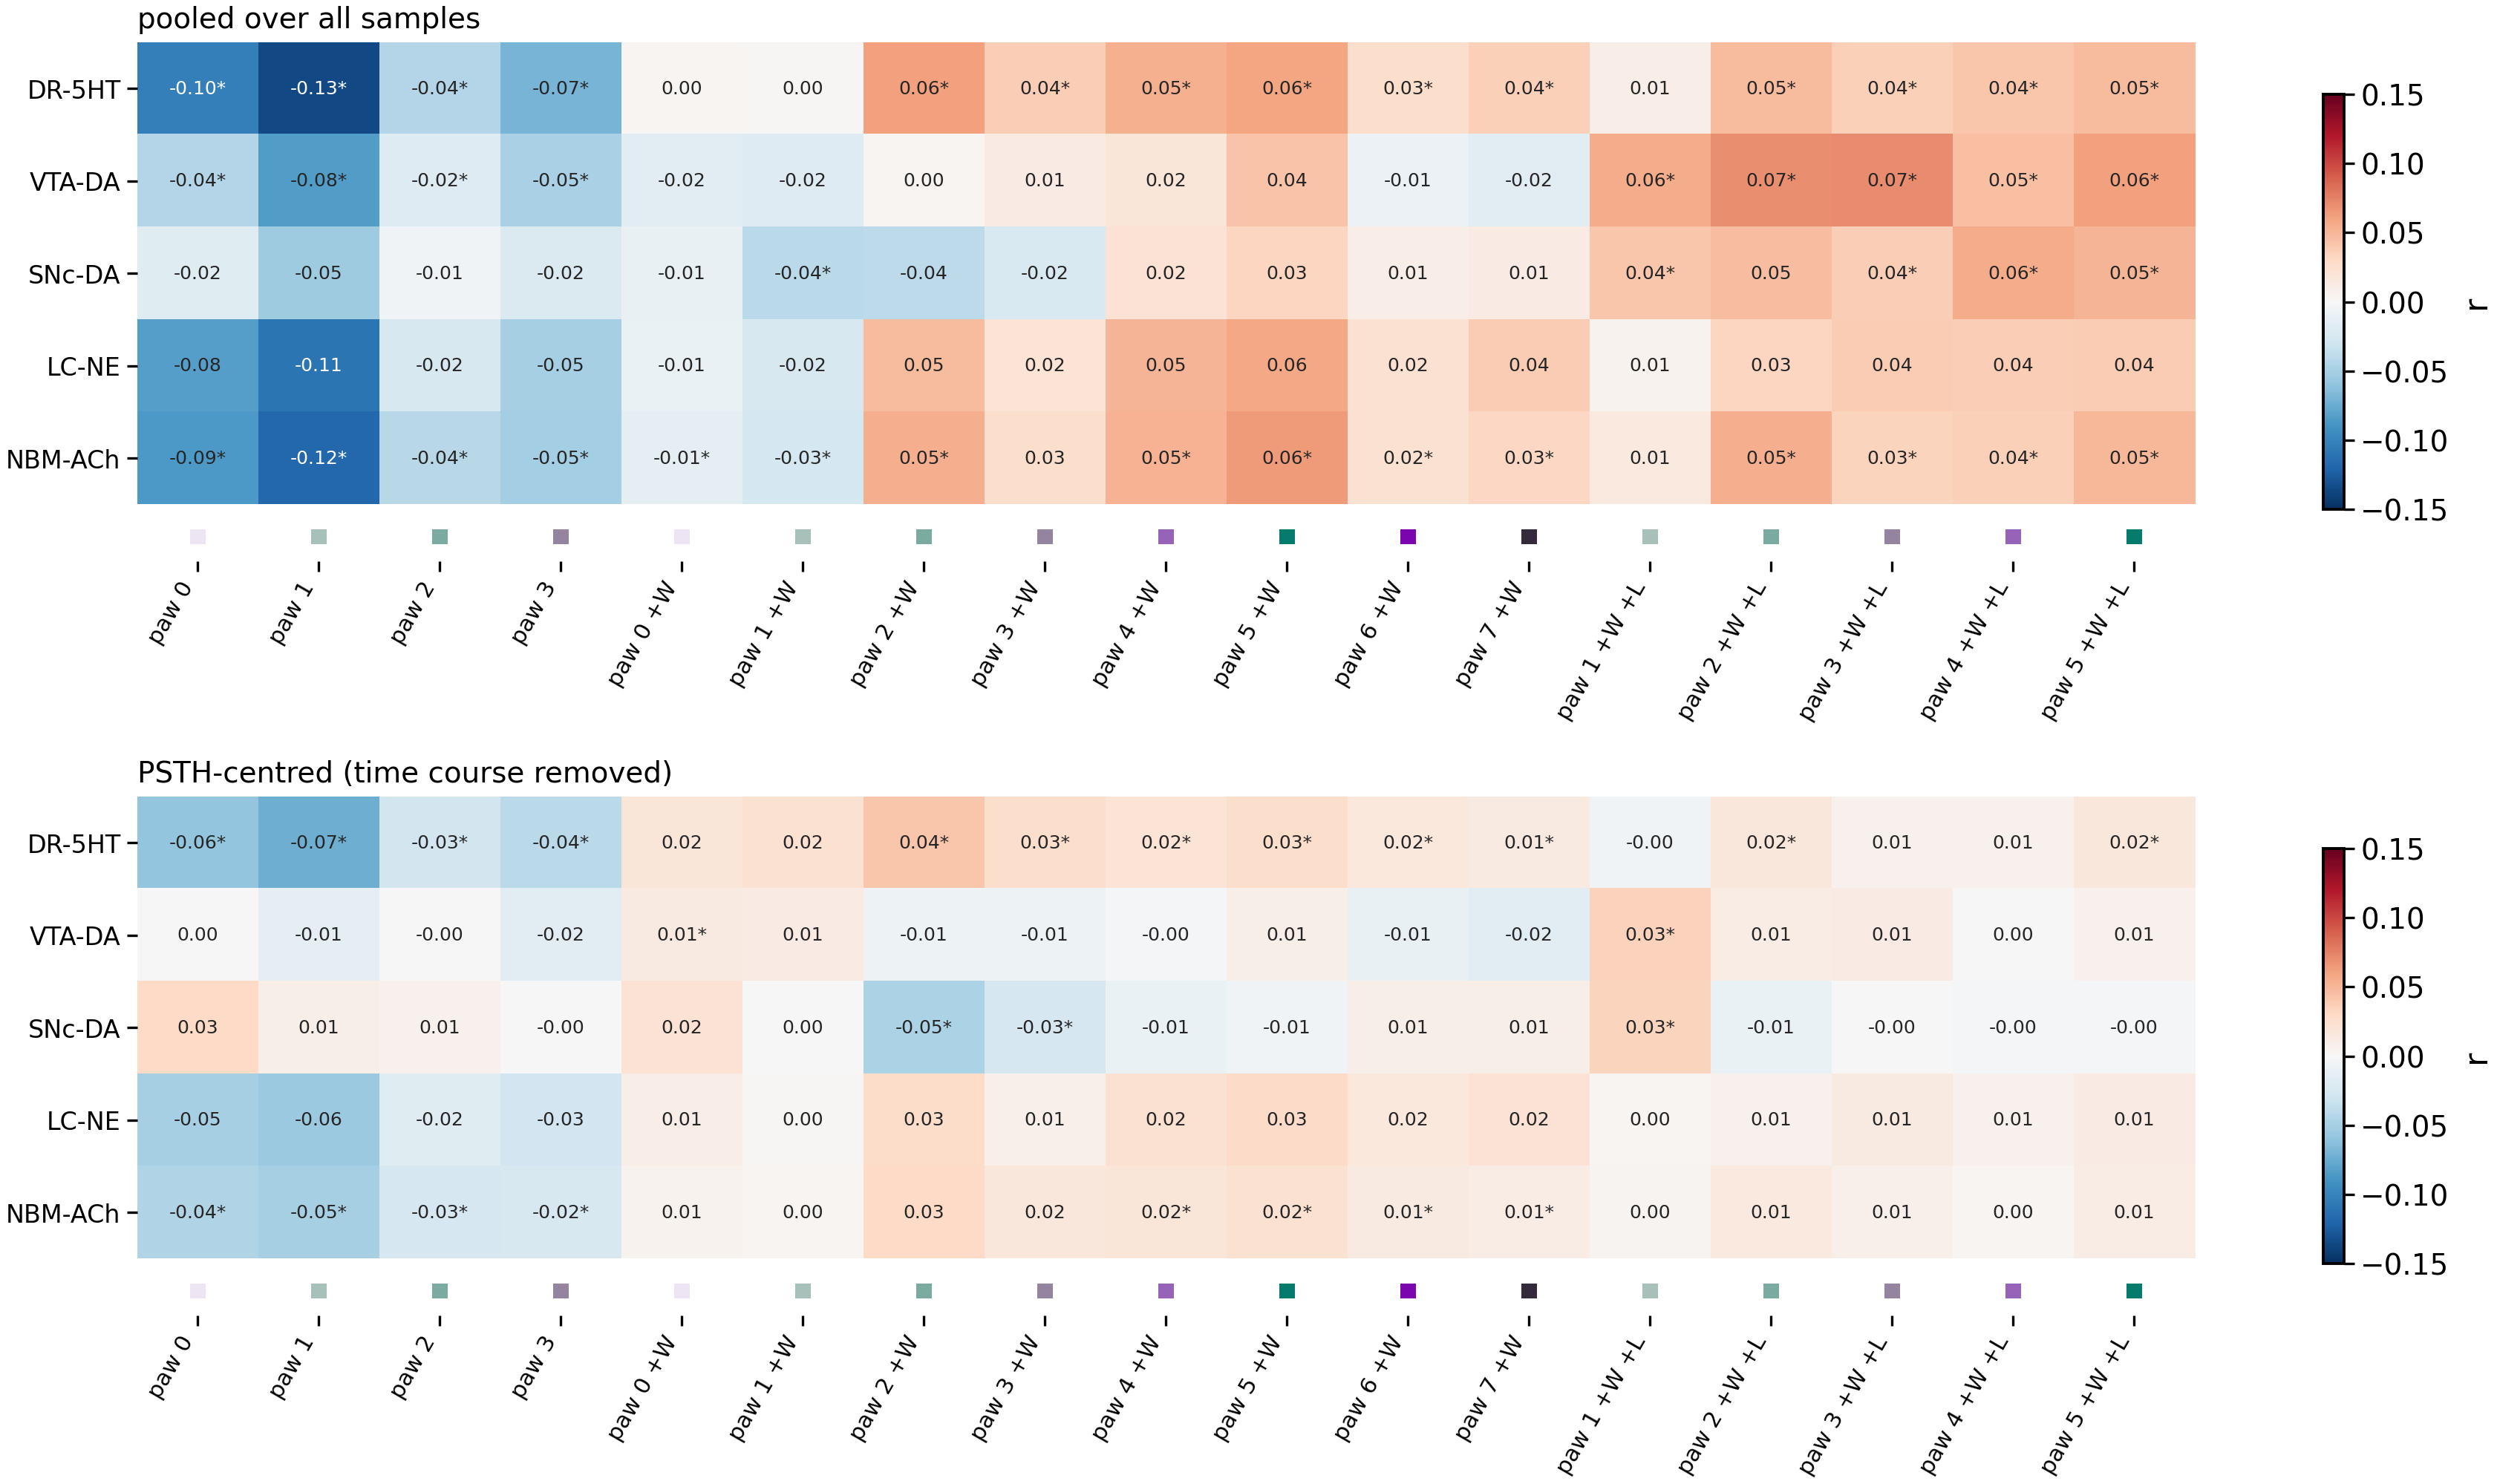

In [10]:
POOLED = {}
for name, feats in [('syllables', sp.syllable_features(COMMON, N_PAW)), ('factored', sp.factored_features(N_PAW))]:
    for centre in (False, True):
        key = f"{name}_{'centred' if centre else 'pooled'}"
        f = CACHE / f'pooled_{key}_{RUN}.pkl'
        if f.exists() and not RECOMPUTE:
            POOLED[key] = pd.read_pickle(f)
        else:
            POOLED[key] = sp.pooled_correlations(meta, STIM, FB, SYL_S, SYL_F, feats, centre=centre)
            POOLED[key].to_pickle(f)
PSUM = {k: sp.summarise_pooled(v) for k, v in POOLED.items()}

def pooled_heatmaps(name, col_colors, lim=0.15):
    fig, axes = plt.subplots(2, 1, figsize=(0.42 * len(PSUM[f'{name}_pooled'][0]['feature'].unique()) + 2.2, 5.2))
    for ax, version in zip(axes, ['pooled', 'centred']):
        summ = PSUM[f'{name}_{version}'][0]
        feats = list(dict.fromkeys(summ['feature']))
        R = summ.pivot(index='target_NM', columns='feature', values='r').reindex(index=NM_ORDER, columns=feats)
        Q = summ.pivot(index='target_NM', columns='feature', values='q').reindex(index=NM_ORDER, columns=feats)
        im = ax.imshow(R.to_numpy(), cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
        for (i, j), v in np.ndenumerate(R.to_numpy()):
            if np.isnan(v):
                continue
            star = '*' if Q.iat[i, j] < 0.05 else ''
            ax.text(j, i, f'{v:.2f}{star}', ha='center', va='center', fontsize=4.5,
                    color='white' if abs(v) > 0.6 * lim else '0.15')
        ax.set_yticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6)
        ax.set_xticks(range(len(feats)), feats, rotation=60, ha='right', fontsize=5.5)
        ax.scatter(range(len(feats)), np.full(len(feats), len(NM_ORDER) - 0.5 + 0.35), marker='s', s=14,
                   c=col_colors, clip_on=False)
        ax.set_title({'pooled': 'pooled over all samples', 'centred': 'PSTH-centred (time course removed)'}[version],
                     fontsize=7, loc='left')
        for sp_ in ax.spines.values():
            sp_.set_visible(False)
        fig.colorbar(im, ax=ax, shrink=0.8, label='r')
    plt.tight_layout(); plt.show()

def per_mouse_dots(name, version, col_colors):
    summ, pm = PSUM[f'{name}_{version}']
    feats = list(dict.fromkeys(summ['feature']))
    fig, axes = plt.subplots(len(NM_ORDER), 1, figsize=(0.42 * len(feats) + 2, 1.35 * len(NM_ORDER)), sharex=True)
    rng = np.random.default_rng(0)
    for ax, nm in zip(axes, NM_ORDER):
        P = pm.loc[nm][feats]
        for j, f in enumerate(feats):
            ax.scatter(j + rng.uniform(-0.15, 0.15, len(P)), P[f], s=6, color=col_colors[j], edgecolor='0.3', lw=0.3, zorder=3)
            ax.plot([j - 0.3, j + 0.3], [P[f].mean()] * 2, color='k', lw=1.2, zorder=4)
        ax.axhline(0, color='0.6', lw=0.6, zorder=0)
        ax.set_ylabel(nm, fontsize=6)
    axes[-1].set_xticks(range(len(feats)), feats, rotation=60, ha='right', fontsize=5.5)
    axes[0].set_title(f'{name}, {version}: r per mouse (dots) and mean (bar)', fontsize=7, loc='left')
    plt.tight_layout(); plt.show()

SCOL = [PAW_COLORS[int(n.split()[1])] for n in POOLED['syllables_pooled'].attrs['features']]
pooled_heatmaps('syllables', SCOL)

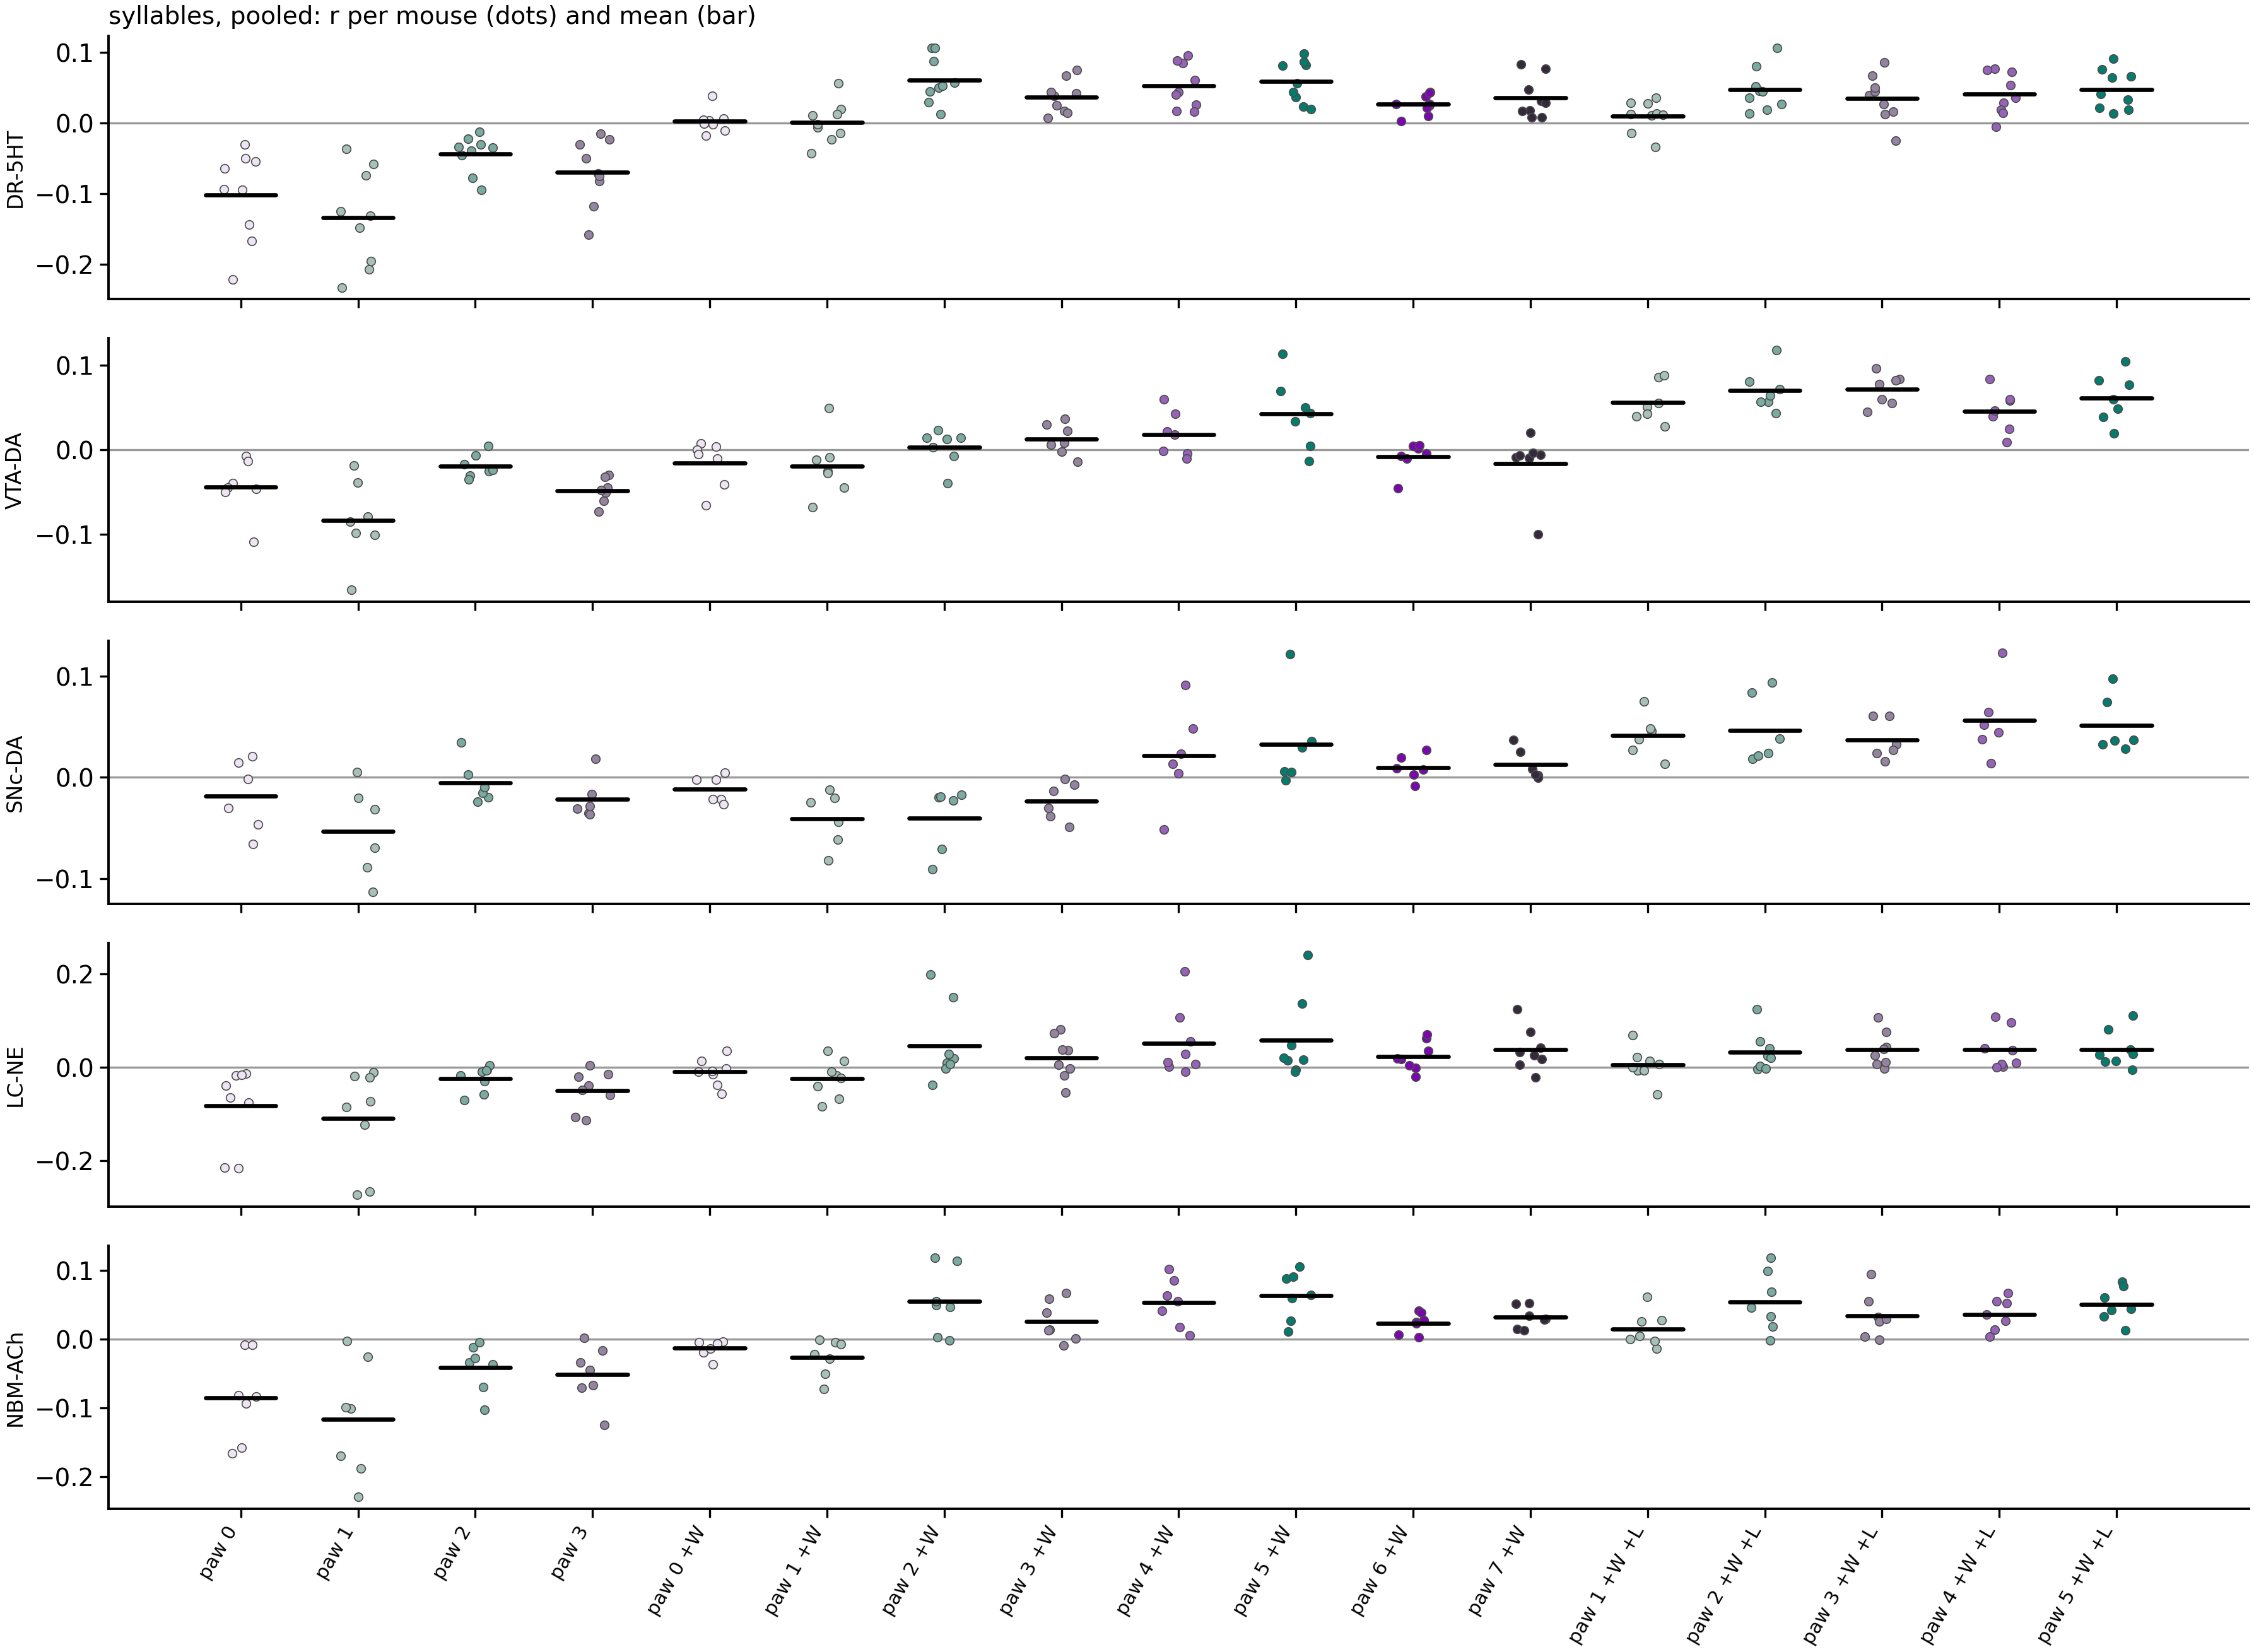

In [11]:
per_mouse_dots('syllables', 'pooled', SCOL)

### Factored features over all samples

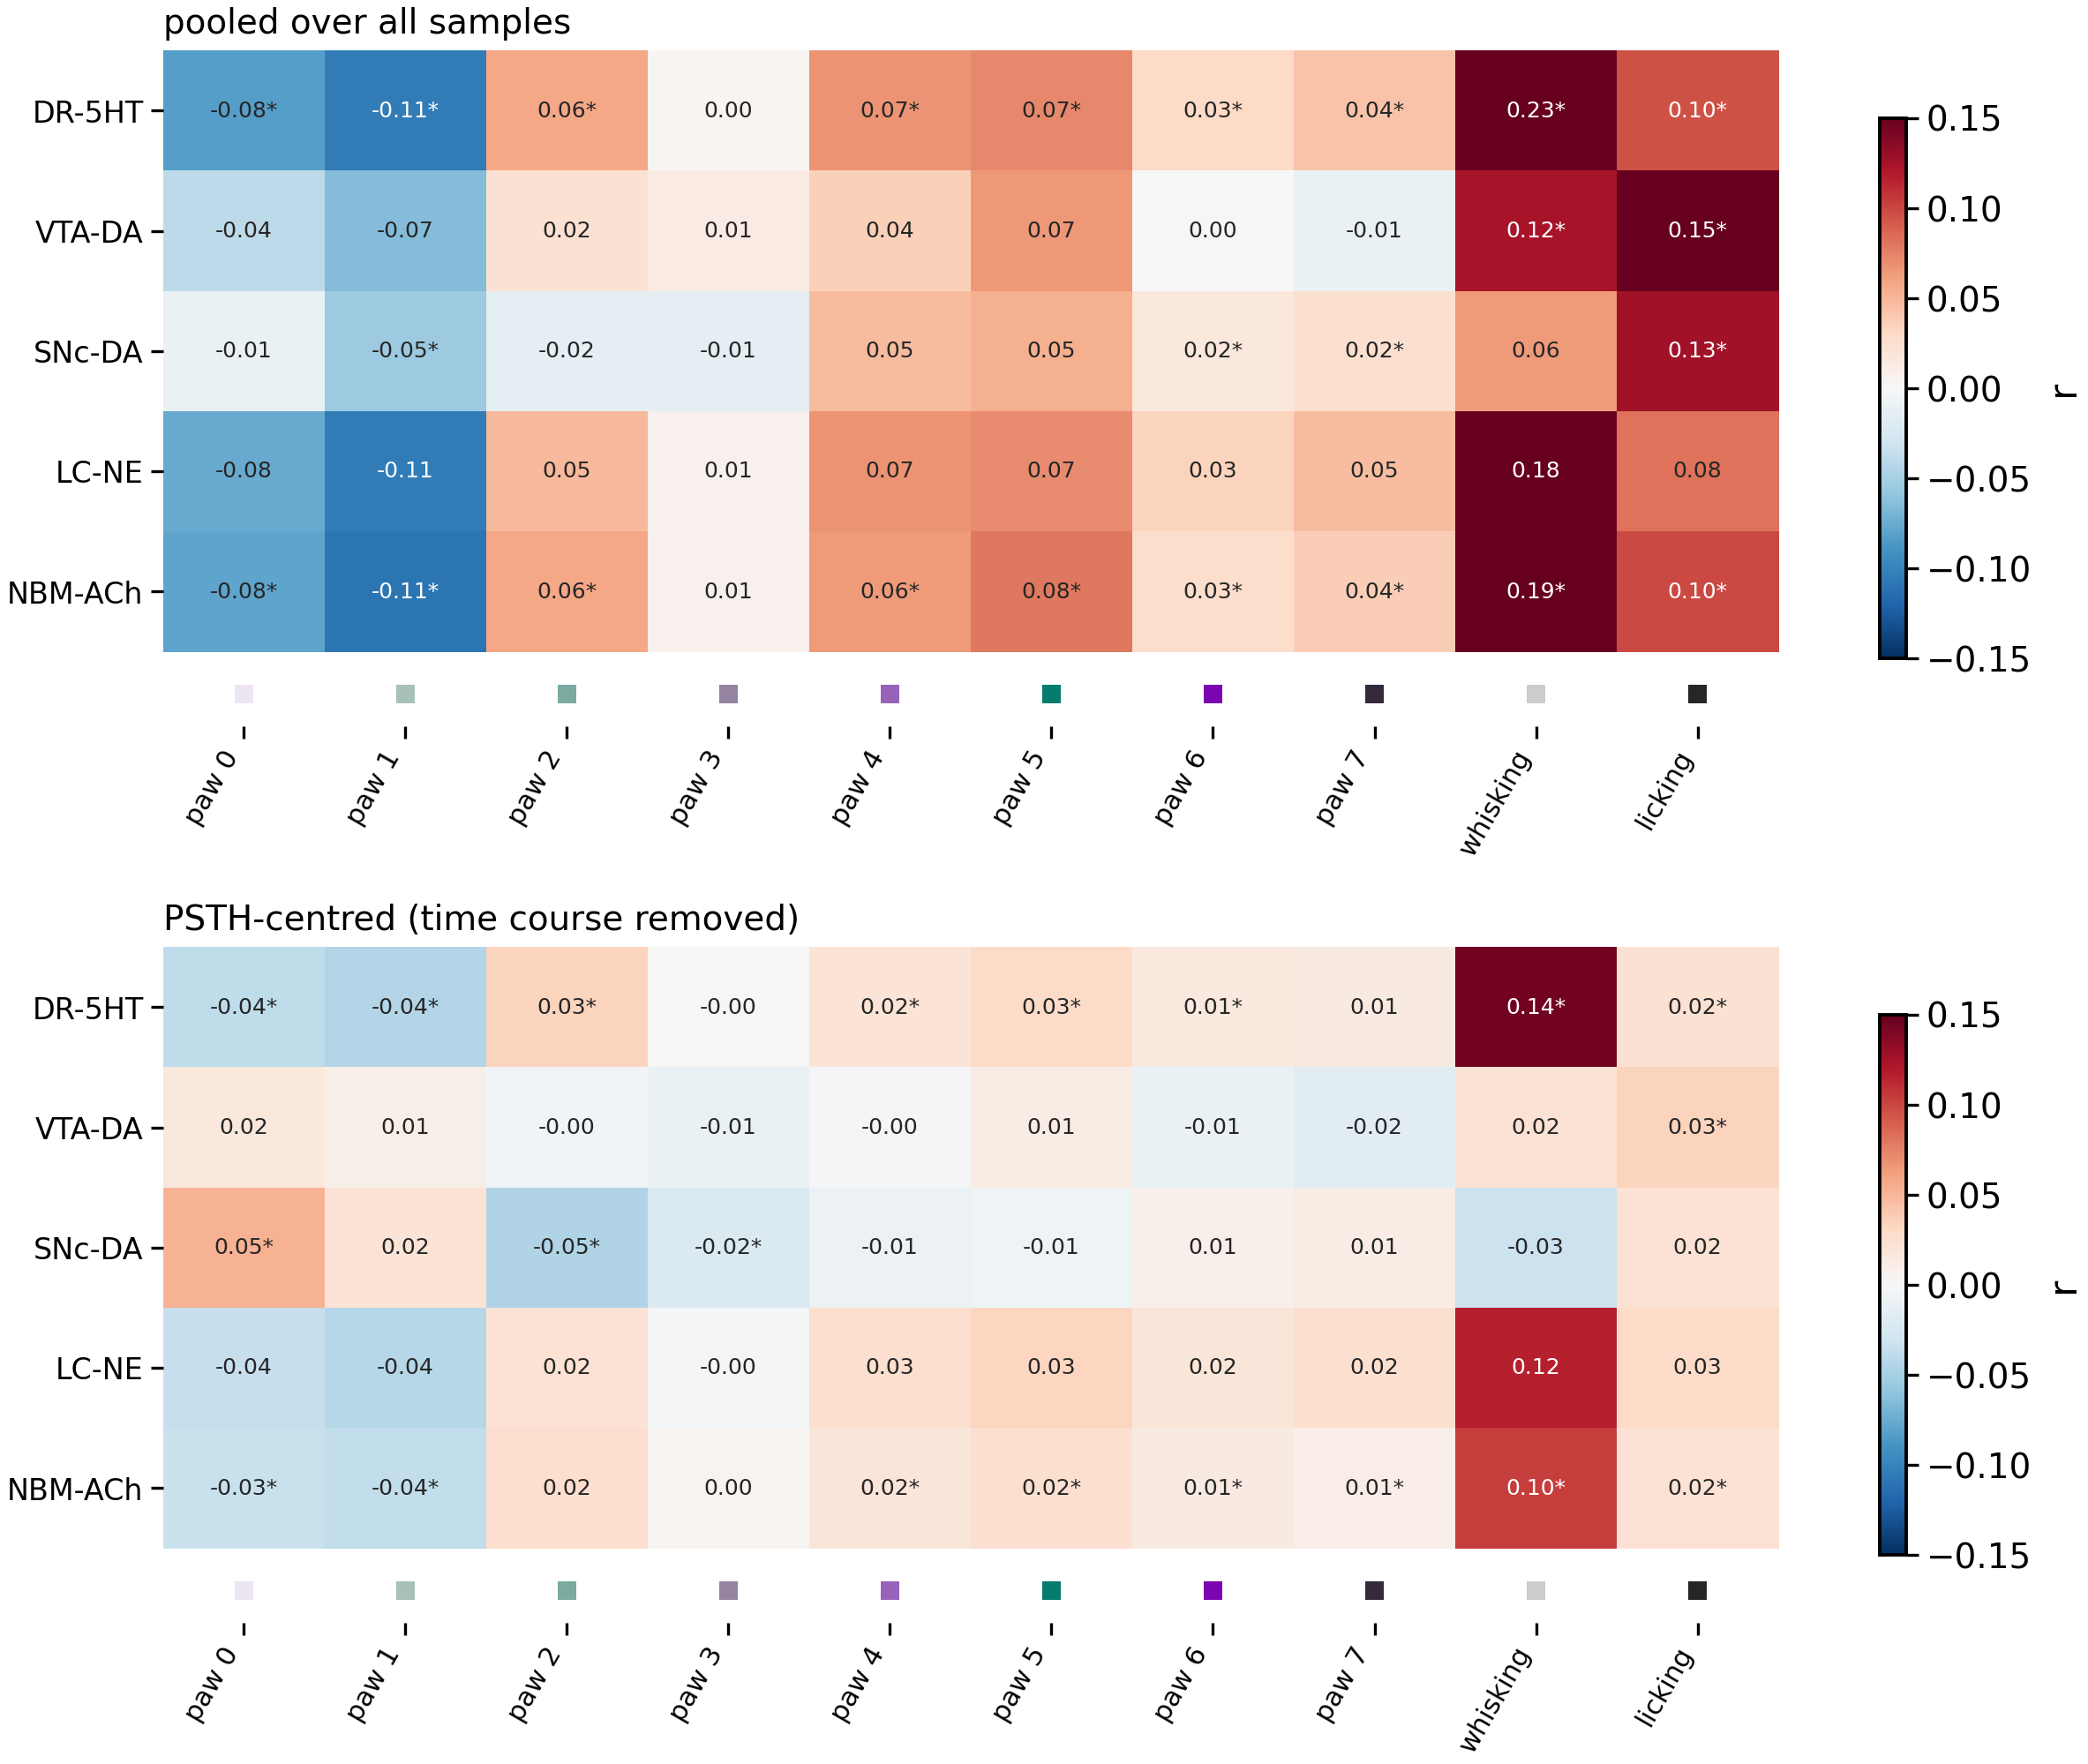

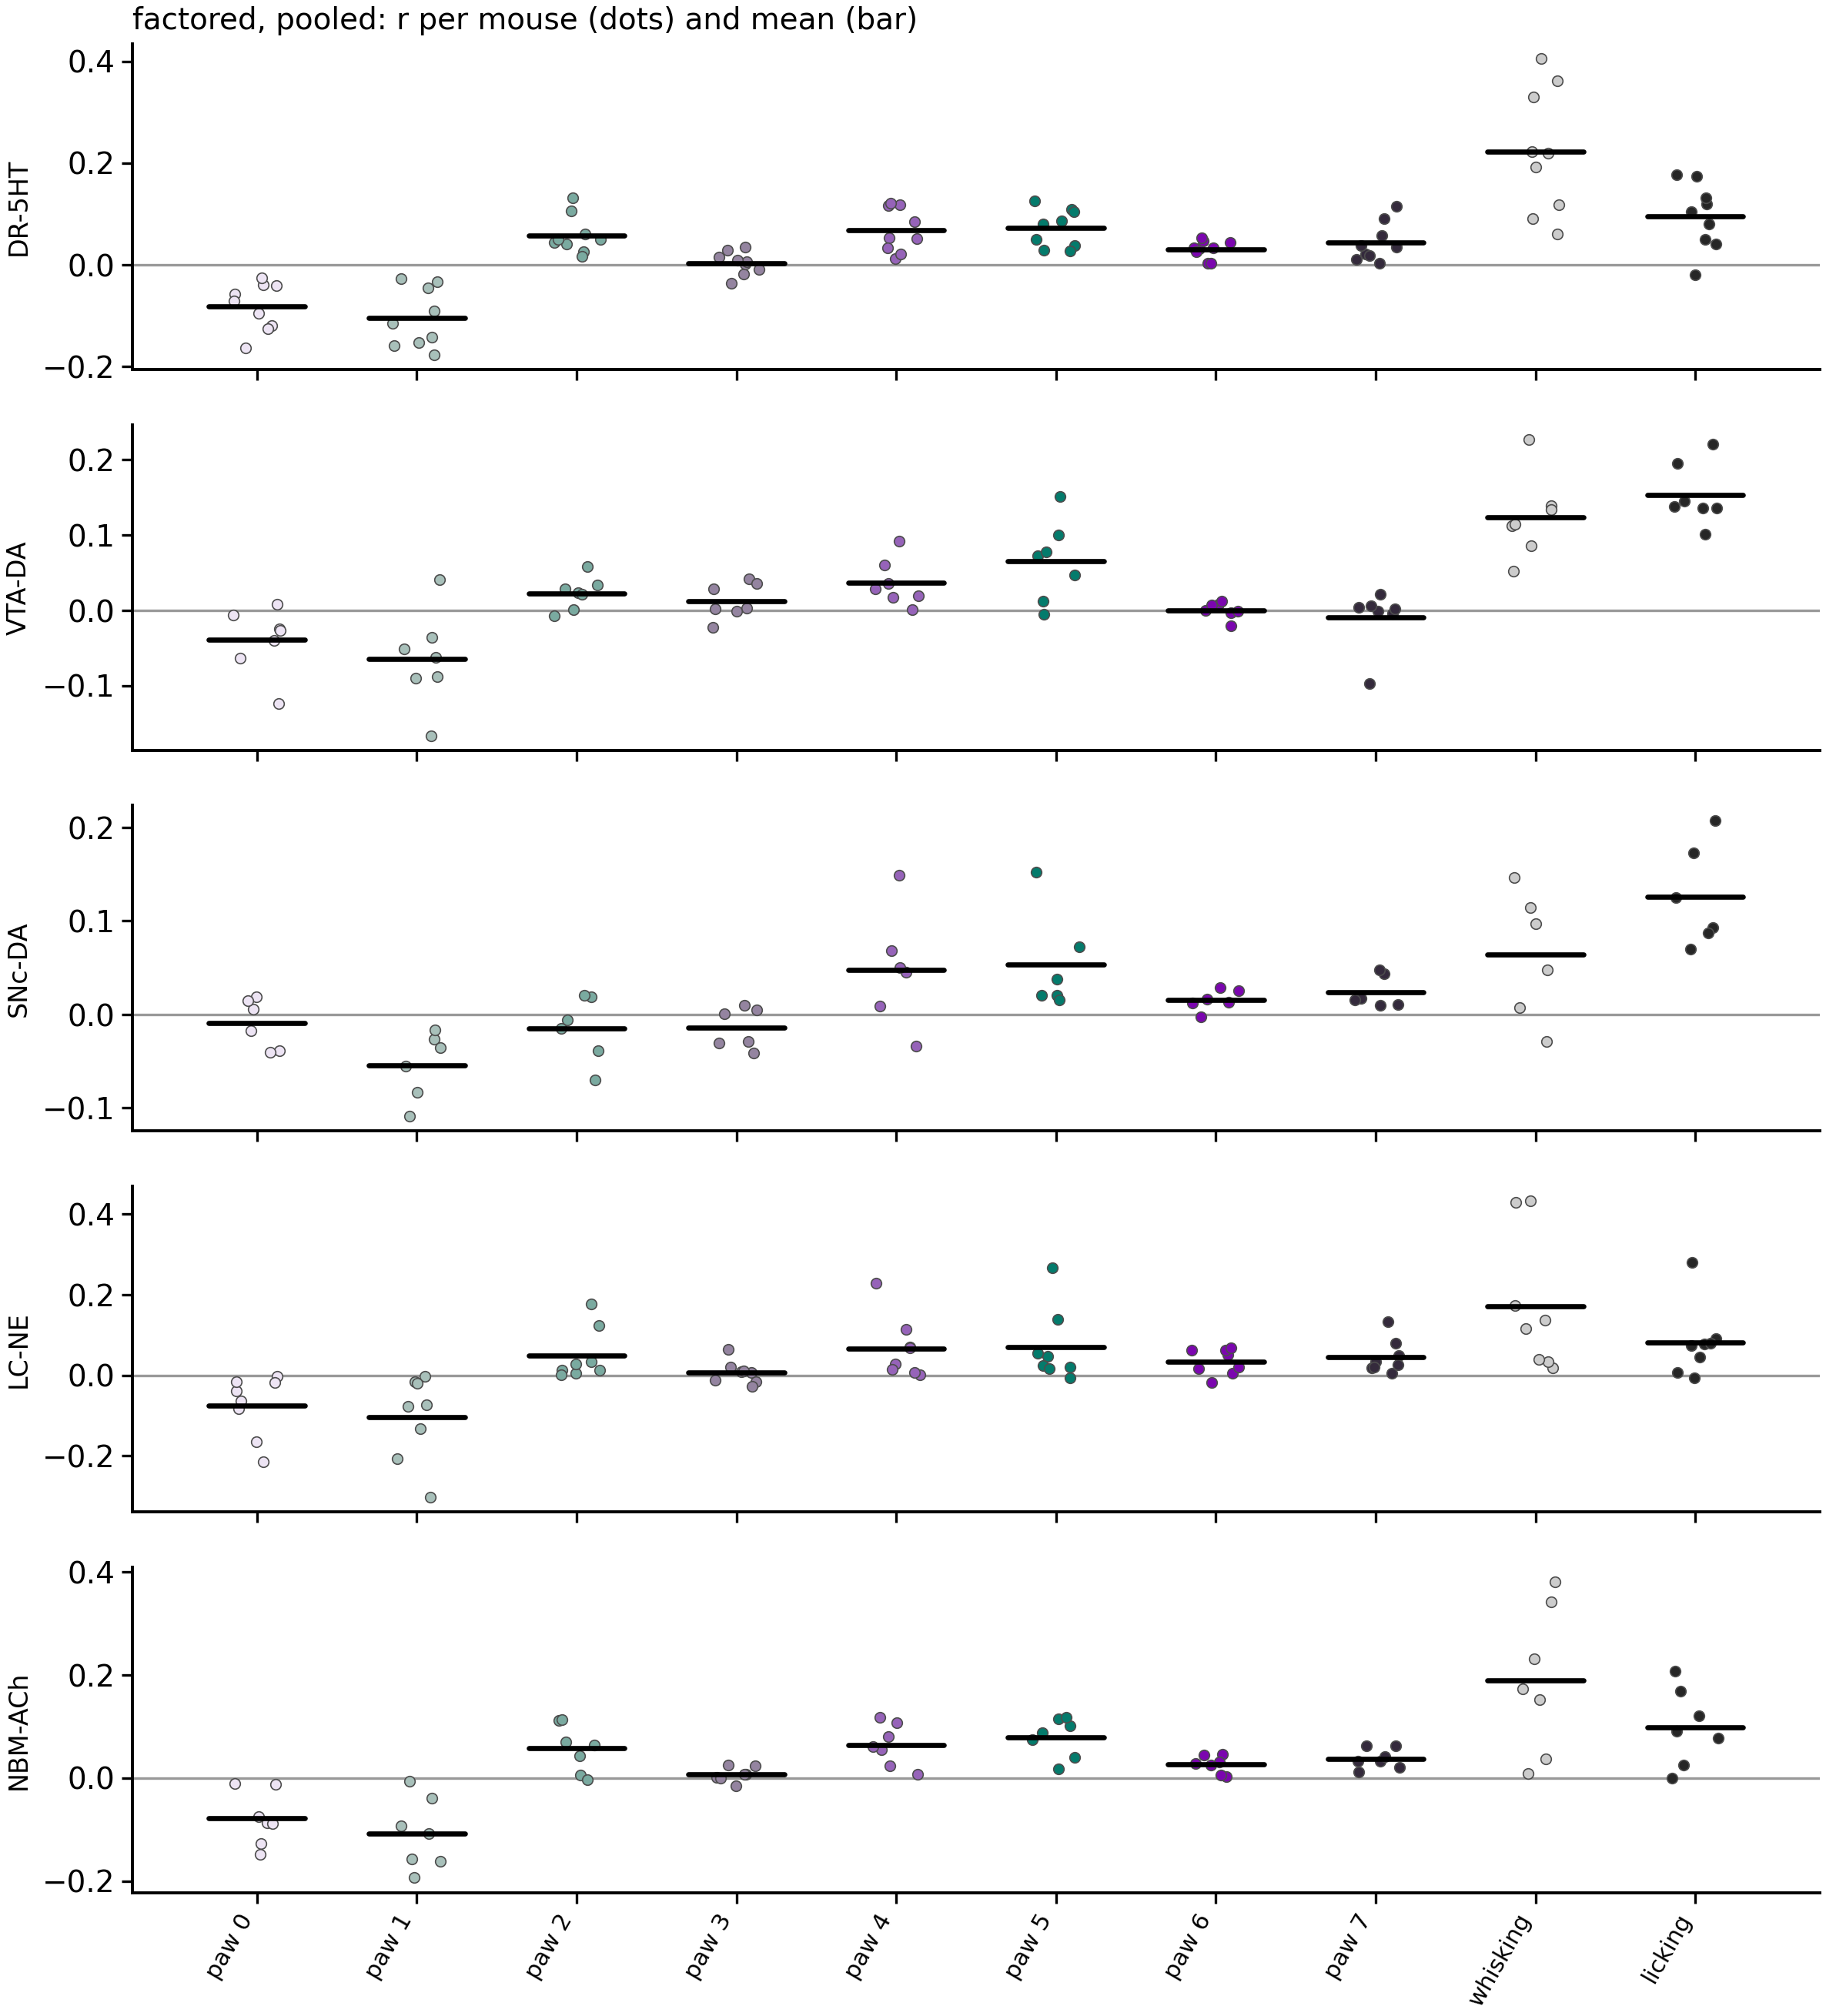

In [12]:
pooled_heatmaps('factored', FCOL)
per_mouse_dots('factored', 'pooled', FCOL)

## Summary

**Data.** The analysis covers 517 fibers from 491 sessions:

| NM | mice | fiber-sessions |
|---|---|---|
| DR-5HT | 9 | 140 |
| VTA-DA | 7 | 141 |
| SNc-DA | 6 | 65 |
| LC-NE | 8 | 96 |
| NBM-ACh | 7 | 75 |

A syllable code is present on 98–99% of the usable photometry samples.

**Within the PSTH, trial by trial** (partial for RT, contrast and trial position):
- **DR-5HT is the clearest.** 36% of feature × sample cells are significant on rewarded trials and 25% on error trials. Whisking is positive in all 9 mice (peak r ≈ 0.24). The still paw states (0, 1) are negative and the active paw states positive, through most of the PSTH.
- **LC-NE and NBM-ACh** have the same signs on average (whisking +, still paw −). But they are driven by 2–3 strongly coupled mice, with the rest near zero. Across mice they barely reach significance.
- **Dopamine is different.**
  - **SNc:** before the stimulus, a still paw goes with *higher* DA (r up to 0.18, all 6 mice) and whisking with *lower* DA (−0.15).
  - **VTA and SNc:** licking around the quiescence period goes with higher DA (≈ 0.11–0.14).
- **Covariates change little.** Removing RT, contrast and trial position lowers the median |r| only slightly. The relations are not just slow-vs-fast trials or drift within the session.

**Over all samples, regardless of PSTH position:**
- **Every NM is lower when the paw is still and higher when whisking.** The whisking r is: DR 0.23, NBM 0.19, LC 0.18, VTA 0.12, SNc 0.06. With full syllables, the most positive codes for DR, NBM and LC are active paw + whisking. For dopamine they are the lick syllables (+W+L, VTA up to 0.07).
- **Licking is the dopamine feature** (VTA 0.15, SNc 0.13).
- **Removing the PSTH time course** (PSTH-centred) separates two kinds of relation:
  - For DR, NBM and LC, whisking stays positive (0.10–0.14). It is a trial-to-trial relation, not just timing.
  - For dopamine, the licking relation mostly disappears (VTA 0.15 → 0.03). It reflects licking and the DA reward response happening at the same time in the trial. For SNc, the sign even flips: a still paw is positive and whisking negative, as in the PSTH-resolved maps.

**Caveats**
- Whisking is an arousal readout, so the 5HT/NE/ACh relations may reflect shared arousal rather than the movement.
- Samples within a trial are autocorrelated. Inference is across mice only, and LC (8 mice, 2 strong) shows how much mice differ.
- Two-fiber sessions (NBM) count each fiber within the mouse average.